In [1]:
# source ~/load_modules_pitts_spack-26.1.sh
# module unload --no-auto py-typing-extensions py-pylint-gitlab -f
# module load py-pip
# OMP_NUM_THREADS=64 DISPLAY= PYTHONPATH=$PYTHONPATH:~/pitts_clean/examples/.python-packages/lib/python3.14/site-packages/:~/pitts_clean/build_intel/src/ .python-packages/bin/jupyter notebook --no-browser --ip=0.0.0.0
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.ndimage import convolve1d
import pitts_py
import timeit
import functools
import pandas as pd
import cartopy.crs as ccrs
from IPython import display
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix, adjusted_rand_score
import cartopy.io.shapereader as shpreader
from shapely.geometry import box
from pyproj import Transformer
from scipy.interpolate import RegularGridInterpolator
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['savefig.transparent'] = False
#plt.rcParams['agg.transparent'] = False

In [2]:
pitts_py.initialize()

PITTS: version v0.9.7-207-gc00bfa6
PITTS: MPI #procs: 1
PITTS: OpenMP #threads: 64
PITTS: SIMD implementation: avx512
PITTS: Eigen SIMD implementation: AVX512, FMA, AVX2, AVX, SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2
PITTS: cache sizes (L1/core, L2/core, L3/accessible) [byte]: (32768, 1048576, 92274688)
PITTS: preprocessor definitions: PITTS_DIRECT_MKL_GEMM


In [3]:
def getCurrentMemoryUsage():
    """Memory usage in GB"""
    # from stackoverflow: https://stackoverflow.com/questions/938733/total-memory-used-by-python-process
    with open('/proc/self/status') as f:
        memusage = f.read().split('VmRSS:')[1].split('\n')[0][:-3]
    return int(memusage.strip()) / 10**6


def timer(func):
    """measure runtime of the decorated function"""
    @functools.wraps(func)
    def wrapper_fun(*args, **kwargs):
        mem_before = getCurrentMemoryUsage()
        wtime = timeit.default_timer()
        value = func(*args, **kwargs)
        wtime = timeit.default_timer() - wtime
        mem_after = getCurrentMemoryUsage()
        from mpi4py import MPI
        if MPI.COMM_WORLD.Get_rank() == 0:
            print(func.__name__, "wtime:", wtime, "memory useage (GB) before/after:", mem_before, mem_after)
        return value
    return wrapper_fun

In [4]:
def _dict_to_tensortrain(tt_dict):
    """helper function to transform file-layout to actual pitts_py type"""
    Xtt = pitts_py.TensorTrain_float(tt_dict['dimensions'])
    Xtt.setTTranks(tt_dict['ranks'])
    for i in range(len(Xtt.dimensions())):
        Xtt.setSubTensor(i, tt_dict['cores'][i])
    return Xtt

@timer
def load_tensortrain(tt_file_name):
    """Load tensor-train from disk"""
    xtt_dict = np.load(tt_file_name, allow_pickle=True)
    Xtt = _dict_to_tensortrain(xtt_dict)
    print(f'Loaded file "{tt_file_name}" to', Xtt)
    return Xtt

In [7]:
# Xtt_ERA5_transposed_24h_.npz - 0.001 tolerance
# Xtt_ERA5_transposed_24h.npz - 0.01 tolerance
Xtt = load_tensortrain('Xtt_ERA5_transposed_24h_.npz')

Loaded file "Xtt_ERA5_transposed_24h_.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1870, 1645, 1450, 1415, 1236, 1246, 1267, 1318, 873, 444, 157]
load_tensortrain wtime: 12.26283873617649 memory useage (GB) before/after: 0.667208 1.145088


In [8]:
dims = Xtt.dimensions()
feature_dims = dims[-7:]
assert np.prod(feature_dims) == 240*480
sample_dims = dims[:-7]
assert sample_dims + feature_dims == dims

In [10]:
#for i in range(len(Xtt.dimensions())):
#    subT = Xtt.getSubTensor(i)
#    left = np.einsum('ijk,ijl->kl', subT, subT)
#    right = np.einsum('ijk,ljk->il', subT, subT)
#    print('Dim', i, 'left', np.linalg.norm(left - np.eye(*left.shape)) < 1.e-3, 'right', np.linalg.norm(right - np.eye(*right.shape)) < 1.e-3)

In [29]:
@timer
def formCosineSimilarity(Xtt, sample_dims, tolerance):
    """form U S^2 U^T (Gram matrix / cosine similarity) in compressed form - assumes Xtt features are normalized"""
    assert sample_dims == Xtt.dimensions()[:len(sample_dims)]
    new_dims = sample_dims + list(reversed(sample_dims))
    dummy_subT = [Xtt.getSubTensor(i) for i in range(len(sample_dims))]
    dummy_subT = dummy_subT + [subT.T for subT in reversed(dummy_subT)]
    dummy_tt = pitts_py.TensorTrain_double(new_dims)
    dummy_tt.setTTranks([subT.shape[2] for subT in dummy_subT[:-1]])
    for i, subT in enumerate(dummy_subT):
        dummy_tt.setSubTensor(i, subT)
    print('Cosine similarity (uncompressed):', dummy_tt)
    Xtt_cosineSimilarity = dummy_tt
    nrm = pitts_py.normalize(Xtt_cosineSimilarity, rankTolerance=tolerance, maxRank=4000)
    print('Cosine similarity (compressed):', Xtt_cosineSimilarity)
    print('Cosine similarity norm:', nrm)
    return nrm, Xtt_cosineSimilarity

In [12]:
nrm, Xtt_cosineSimilarity = formCosineSimilarity(Xtt, sample_dims, 0.001)

Cosine similarity (uncompressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1870, 1645, 1450, 1415, 1236, 1415, 1450, 1645, 1870]
Cosine similarity (compressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [394, 266, 206, 174, 123, 160, 181, 224, 295]
Cosine similarity norm: 209606.27410165768
formCosineSimilarity wtime: 20.974566023796797 memory useage (GB) before/after: 0.900828 3.141464


In [30]:
@timer
def TT_cross_Gaussian(Xtt, nrm, sigma, tolerance, nSweeps, maxRank=2000, enrichmentRank=300, errorRank=400, oversampling=0.5, maxRankMiddle=2000):
    """Approximate elementwise Gaussian RBF kernel function using TCI (tensor-cross interpolation)"""

    def kernel_inplace(values):
        values *= nrm
        values -= 1
        #print('max(1 - g):', np.max(-values))
        #print('max(g - 1):', np.max(values))
        values /= sigma**2
        np.exp(values, out=values)

    dims = Xtt.dimensions()
    maxRanks = [maxRank,]*(len(dims)-1)
    maxRanks[len(dims)//2-1] = maxRankMiddle

    Ytt = pitts_py.TensorTrain_double(dims)
    pitts_py.applyElementwise(kernel_inplace, Xtt, Ytt,
                              convergenceTolerance=tolerance, maxRanks=maxRanks, enrichmentRank=enrichmentRank, errorRank=errorRank, oversampling=oversampling,
                              rankTolerance=0.2*tolerance, nMALS=1, nSweeps=nSweeps, controlSampleSize=10000, verbose=True, maxvolTolerance=0.1)
    print('Applied Gaussian kernel', Ytt)
    return Ytt

In [14]:
Xtt_Gaussian = TT_cross_Gaussian(Xtt_cosineSimilarity, nrm, sigma=1, tolerance=0.005, nSweeps=4, maxRank=3000, maxRankMiddle=3000, enrichmentRank=500, errorRank=1000)

TT-cross sweep 0.5: change 1.27571, error estimate 1.68259, sampled error 0.0131546, ranks: 858 753 697 670 623 660 681 724 795
TT-cross sweep 1: change 0.00644612, error estimate 0.0112356, sampled error 0.00995061, ranks: 829 687 623 594 586 619 652 703 783
TT-cross sweep 1.5: change 0.00660474, error estimate 0.0107146, sampled error 0.00745823, ranks: 1318 1178 1115 1087 1078 1111 1144 1195 1275
TT-cross sweep 2: change 0.00341971, error estimate 0.00684859, sampled error 0.006529, ranks: 1256 1087 1008 985 995 1029 1080 1149 1250
TT-cross sweep 2.5: change 0.00407432, error estimate 0.00780997, sampled error 0.00572457, ranks: 1728 1561 1483 1459 1464 1497 1547 1618 1722
TT-cross sweep 3: change 0.00268553, error estimate 0.00556367, sampled error 0.00519892, ranks: 1613 1407 1309 1285 1301 1353 1427 1530 1674
TT-cross sweep 3.5: change 0.00297625, error estimate 0.00623373, sampled error 0.00484476, ranks: 2068 1862 1764 1735 1741 1788 1857 1961 2113
TT-cross sweep 4: change 0.00

In [31]:
@timer
def normalize(Xtt, tolerance, maxRank=2000):
    nrm = pitts_py.normalize(Xtt, rankTolerance=tolerance, maxRank=maxRank)
    Xtt.setSubTensor(0, nrm*Xtt.getSubTensor(0))
    print(Xtt)

In [16]:
normalize(Xtt, 0.001)

PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1867, 1541, 1307, 1201, 1016, 1015, 1016, 939, 570, 241, 74]
normalize wtime: 11.293315375223756 memory useage (GB) before/after: 7.627152 7.642508


In [32]:
@timer
def TT_centerSVD(Xtt_Gaussian):
    """Calculate the SVD at the middle bond - merges S into the sub-tensor right from the middle"""
    # ensure sufficient orthogonality
    dims = Xtt_Gaussian.dimensions()
    pitts_py.internal.ensureLeftOrtho_range(Xtt_Gaussian, 0, len(dims)//2)
    pitts_py.internal.ensureRightOrtho_range(Xtt_Gaussian, len(dims)//2, len(dims)-1)

    subTr = Xtt_Gaussian.getSubTensor(len(dims)//2)
    # print('old shape', subTr.shape)
    U, S, Vt = np.linalg.svd(subTr.reshape((subTr.shape[0], subTr.shape[1]*subTr.shape[2]), order='F'), full_matrices=False)
    subTl = Xtt_Gaussian.getSubTensor(len(dims)//2-1)
    subTl = np.einsum('ijk,kl->ijl', subTl, U)
    subTr = (np.diag(S) @ Vt).reshape((S.shape[0], subTr.shape[1], subTr.shape[2]), order='F')
    # print('new shape', subTr.shape)
    Xtt_Gaussian.setSubTensor(len(dims)//2-1, subTl)
    Xtt_Gaussian.setSubTensor(len(dims)//2, subTr)
    return S

@timer
def TT_centerSVD_extractEigenvectors(Xtt, n, tolerance=1.e-4):
    """Assumes a symmetric (wrt. the middle bond dimension) tensor-train and that TT_centerSVD was called before"""
    dims = Xtt.dimensions()
    # take from the left and transpose
    subTs = list(reversed([Xtt.getSubTensor(i).T for i in range(len(dims)//2)]))
    subTs[0] = subTs[0][:n,:,:]
    I = np.eye(n, n, dtype=np.float32).reshape((1,n,n), order='C', copy=False)
    subTs = [I,] + subTs

    tt = pitts_py.TensorTrain_double([subT.shape[1] for subT in subTs])
    tt.setTTranks([subT.shape[2] for subT in subTs[:-1]])
    for i, subT in enumerate(subTs):
        tt.setSubTensor(i, subT)
    print('top eigenvectors (uncompressed):', tt)
    nrm = pitts_py.normalize(tt, rankTolerance=tolerance)
    tt.setSubTensor(0, tt.getSubTensor(0)*nrm)
    print('top eigenvectors (compressed):', tt)
    return tt

In [18]:
#for i in range(len(Xtt_Gaussian.dimensions())):
#    subT = Xtt_Gaussian.getSubTensor(i)
#    left = np.einsum('ijk,ijl->kl', subT, subT)
#    right = np.einsum('ijk,ljk->il', subT, subT)
#    print('Dim', i, 'left', np.linalg.norm(left - np.eye(*left.shape)) < 1.e-4, 'right', np.linalg.norm(right - np.eye(*right.shape)) < 1.e-4)

In [19]:
S = TT_centerSVD(Xtt_Gaussian)

TT_centerSVD wtime: 9.97438477911055 memory useage (GB) before/after: 7.64252 7.64308


In [33]:
@timer
def TT_matrixRowSum(Xtt, tolerance=1.e-5):
    """Consider the matrix resulting from splitting the TT in the middle and calculate its row-sum in TT format"""
    tmp = np.ones((1,))
    dims = Xtt.dimensions()
    for i in range(len(dims)//2):
        subT = Xtt.getSubTensor(len(dims)-i-1)
        tmp = subT.reshape((subT.shape[0]*subT.shape[1],subT.shape[2]), order='F') @ tmp
        tmp = tmp.reshape((subT.shape[0], subT.shape[1]), order='F')
        tmp = np.sum(tmp, axis=1)
    # sub-tensor left from the middle
    subT = Xtt.getSubTensor(len(dims)//2-1)
    last_subT = subT.reshape((subT.shape[0]*subT.shape[1], subT.shape[2]), order='F') @ tmp
    last_subT = last_subT.reshape((subT.shape[0], subT.shape[1], 1), order='F')
    tt = pitts_py.TensorTrain_double(dims[:len(dims)//2])
    new_subT = [Xtt.getSubTensor(i) for i in range(len(dims)//2-1)] + [last_subT,]
    tt.setTTranks([subT.shape[2] for subT in new_subT[:-1]])
    for i, subT in enumerate(new_subT):
        tt.setSubTensor(i, subT)

    print('row-sum (uncompressed)', tt)
    nrm = pitts_py.normalize(tt, rankTolerance=tolerance)
    tt.setSubTensor(0, tt.getSubTensor(0)*nrm)
    print('row-sum (compressed)', tt)
    return tt

In [21]:
d_tt = TT_matrixRowSum(Xtt_Gaussian)

row-sum (uncompressed) PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2]
             ranks      = [1893, 1636, 1520, 1494]
row-sum (compressed) PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2]
             ranks      = [12, 7, 4, 2]
TT_matrixRowSum wtime: 9.115911727771163 memory useage (GB) before/after: 7.643084 7.643464


In [34]:
@timer
def TT_symmetricDyadicProduct(d_tt):
    """Construct a symmetric product of a tensor-train v = v v^T where v is in QTT format"""
    dims = d_tt.dimensions()
    dims = dims + list(reversed(dims))
    D_tt = pitts_py.TensorTrain_double(dims)
    D_subT = [d_tt.getSubTensor(i) for i in range(len(dims)//2)]
    D_subT += [subT.T for subT in reversed(D_subT)]
    D_tt.setTTranks([subT.shape[2] for subT in D_subT[:-1]])
    for i, subT in enumerate(D_subT):
        D_tt.setSubTensor(i, subT)
    print("Symmetric dyadic product TT:", D_tt)
    return D_tt

In [23]:
D_tt = TT_symmetricDyadicProduct(d_tt)

Symmetric dyadic product TT: PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [12, 7, 4, 2, 1, 2, 4, 7, 12]
TT_symmetricDyadicProduct wtime: 0.012478705495595932 memory useage (GB) before/after: 7.643464 7.643464


In [35]:
@timer
def TT_vectorRowSum(Xtt, tolerance=1.e-5):
    """Consider the vector represented by the TT its row-sum"""
    tmp = np.ones((1,))
    dims = Xtt.dimensions()
    for i in range(len(dims)):
        subT = Xtt.getSubTensor(len(dims)-i-1)
        tmp = subT.reshape((subT.shape[0]*subT.shape[1],subT.shape[2]), order='F') @ tmp
        tmp = tmp.reshape((subT.shape[0], subT.shape[1]), order='F')
        tmp = np.sum(tmp, axis=1)
    assert tmp.shape == (1,)
    print('rowSum: ', tmp)
    return tmp[0]

In [25]:
vol = TT_vectorRowSum(d_tt)

rowSum:  [2.17465614e+11]
TT_vectorRowSum wtime: 0.011717218905687332 memory useage (GB) before/after: 7.643464 7.643464


In [36]:
# unused - deflated variant is more accurate
@timer
def TT_scaleBySqrtInv(Xtt, Dtt, tolerance, nSweeps, maxRank=2000, maxRankMiddle=2000):
    """Approximate element-wise Xtt / sqrt(Dtt) using TCI (tensor-cross interpolation)"""
    Ytt = pitts_py.TensorTrain_double(Xtt.dimensions())
    def scale_inplace(val1, val2):
        np.divide(val1, np.sqrt(val2), out=val1)

    dims = Xtt.dimensions()
    maxRanks = [maxRank,]*(len(dims)-1)
    maxRanks[len(dims)//2-1] = maxRankMiddle
    
    pitts_py.applyElementwise(scale_inplace, Xtt, Dtt, Ytt,
                              convergenceTolerance=tolerance, maxRanks=maxRanks, enrichmentRank=50, errorRank=100, oversampling=0.5,
                              rankTolerance=0.3*tolerance, nMALS=1, nSweeps=nSweeps, controlSampleSize=10000, verbose=True, maxvolTolerance=0.1)
    print("Scaling by 1/sqrt(D):", Ytt)
    return Ytt

In [27]:
Xtt_Gaussian_normalized = TT_scaleBySqrtInv(Xtt_Gaussian, D_tt, tolerance=0.001, nSweeps=3)

TT-cross sweep 0.5: change 1, error estimate 1.01564, sampled error 0.00028576, ranks: 1937 1680 1563 1534 1531 1578 1677 1838 2000
TT-cross sweep 1: change 0.000389394, error estimate 0.000777212, sampled error 0.000581581, ranks: 1885 1621 1505 1477 1479 1513 1605 1766 1983
Scaling by 1/sqrt(D): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1885, 1621, 1505, 1477, 1479, 1513, 1605, 1766, 1983]
TT_scaleBySqrtInv wtime: 291.493574000895 memory useage (GB) before/after: 7.643548 9.457224


In [37]:
# directly construct a scaled variant of the Gaussian using TT-cross
@timer
def TT_cross_Gaussian_scaled(Xtt, nrm, Dtt, Dtt_vol, sigma, tolerance, nSweeps, maxRank=2000, enrichmentRank=300, errorRank=400, oversampling=0.5, maxRankMiddle=2000):
    """Approximate elementwise Gaussian RBF kernel function with scaling and deflating the Fiedler vector using TCI (tensor-cross interpolation)"""

    def kernel_inplace(values, D):
        values *= nrm
        values -= 1
        #print('max(1 - g):', np.max(-values))
        #print('max(g - 1):', np.max(values))
        values /= sigma**2
        np.exp(values, out=values)
        sqrt_D = np.sqrt(D)
        np.divide(values, sqrt_D, out=values)
        sqrt_D /= Dtt_vol
        values -= sqrt_D

    dims = Xtt.dimensions()
    maxRanks = [maxRank,]*(len(dims)-1)
    maxRanks[len(dims)//2-1] = maxRankMiddle

    Ytt = pitts_py.TensorTrain_double(dims)
    pitts_py.applyElementwise(kernel_inplace, Xtt, Dtt, Ytt,
                              convergenceTolerance=tolerance, maxRanks=maxRanks, enrichmentRank=enrichmentRank, errorRank=errorRank, oversampling=oversampling,
                              rankTolerance=0.1*tolerance, nMALS=1, nSweeps=nSweeps, controlSampleSize=10000, verbose=True, maxvolTolerance=0.1)
    print('Applied scaled, deflated Gaussian kernel', Ytt)
    return Ytt

In [29]:
# Required tolerance for the deflated variant
# s = np.linalg.norm(S)**2-1
# np.sqrt((1+s)/s)
# -> approx 3.7

In [30]:
Xtt_Gaussian_normalized_deflated = TT_cross_Gaussian_scaled(Xtt_cosineSimilarity, nrm, D_tt, vol, sigma=1, tolerance=0.015, nSweeps=4, maxRank=3000, maxRankMiddle=3000, enrichmentRank=500, errorRank=1000)

TT-cross sweep 0.5: change 1, error estimate 1.27982, sampled error 0.0486577, ranks: 897 771 709 676 624 662 685 731 807
TT-cross sweep 1: change 0.0269163, error estimate 0.0501056, sampled error 0.0354698, ranks: 891 744 675 632 609 646 677 726 804
TT-cross sweep 1.5: change 0.0273314, error estimate 0.0452363, sampled error 0.0266728, ranks: 1388 1242 1173 1131 1108 1145 1176 1225 1303
TT-cross sweep 2: change 0.0129071, error estimate 0.0272679, sampled error 0.0233363, ranks: 1375 1213 1126 1078 1075 1115 1156 1212 1298
TT-cross sweep 2.5: change 0.0161757, error estimate 0.0324166, sampled error 0.0194587, ranks: 1868 1706 1619 1571 1568 1607 1649 1705 1792
TT-cross sweep 3: change 0.0098935, error estimate 0.0226318, sampled error 0.0173869, ranks: 1843 1663 1560 1509 1513 1553 1610 1682 1782
TT-cross sweep 3.5: change 0.0116371, error estimate 0.0266077, sampled error 0.0151313, ranks: 2329 2147 2044 1992 1992 2031 2089 2164 2268
TT-cross sweep 4: change 0.00802916, error esti

In [31]:
#for i in range(len(Xtt_Gaussian_normalized.dimensions())):
#    subT = Xtt_Gaussian_normalized.getSubTensor(i)
#    left = np.einsum('ijk,ijl->kl', subT, subT)
#    right = np.einsum('ijk,ljk->il', subT, subT)
#    print('Dim', i, 'left', np.linalg.norm(left - np.eye(*left.shape)) < 1.e-4, 'right', np.linalg.norm(right - np.eye(*right.shape)) < 1.e-4)

In [32]:
S_deflated = TT_centerSVD(Xtt_Gaussian_normalized_deflated)

TT_centerSVD wtime: 26.441596383228898 memory useage (GB) before/after: 12.121392 11.869848


In [33]:
S = TT_centerSVD(Xtt_Gaussian_normalized)

TT_centerSVD wtime: 7.437410816550255 memory useage (GB) before/after: 11.869848 11.869848


deflated [0.1524599  0.12100713 0.11284566 0.08752751 0.06890353 0.05881725
 0.05131284 0.04457237 0.03467408 0.03094494 0.02870118 0.02266277
 0.01993822 0.01625448 0.01493695 0.01428218 0.01387649 0.01282648
 0.01218948 0.01134536]
normal [0.99999851 0.15241783 0.120968   0.11281769 0.08751395 0.06887673
 0.05879253 0.05130612 0.04454577 0.03465322 0.03092838 0.02867867
 0.02263716 0.0199261  0.01622707 0.01490932 0.01422752 0.01383651
 0.01280431 0.012165  ]


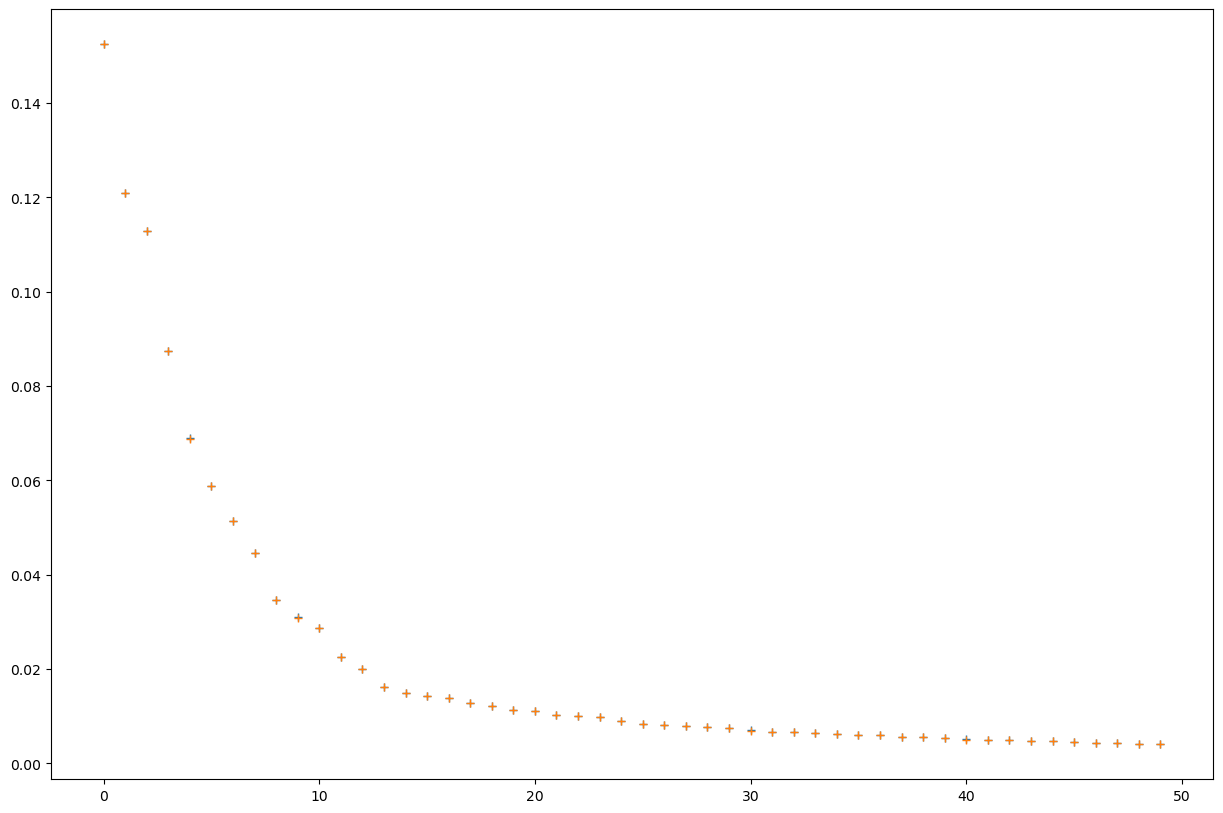

In [34]:
print('deflated', S_deflated[:20])
print('normal', S[:20])
plt.plot(S_deflated[:50], '+')
plt.plot(S[1:51], '+')

In [38]:
@timer
def computeLabels(Xtt_Gaussian_normalized, n_clusters):
    # NJW variant with eigenvector of trivial eigenvalue included
    v_tt = TT_centerSVD_extractEigenvectors(Xtt_Gaussian_normalized, n_clusters, tolerance=1.e-5)
    v = pitts_py.toDense(v_tt)
    v = v.reshape((n_clusters, v.size//n_clusters), order='F', copy=False).T
    v /= np.linalg.norm(v, axis=1, keepdims=True)      # NJW row normalisation
    labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit_predict(v)
    return labels

In [36]:
labels = computeLabels(Xtt_Gaussian_normalized, n_clusters=4)

top eigenvectors (uncompressed): PITTS::TensorTraindouble
        with dimensions = [4, 2, 2, 2, 2, 47118]
             ranks      = [4, 1477, 1505, 1621, 1885]
top eigenvectors (compressed): PITTS::TensorTraindouble
        with dimensions = [4, 2, 2, 2, 2, 47118]
             ranks      = [4, 8, 15, 29, 57]
TT_centerSVD_extractEigenvectors wtime: 7.094615235924721 memory useage (GB) before/after: 11.872388 11.920528
computeLabels wtime: 12.609423574060202 memory useage (GB) before/after: 11.872388 11.884244


In [39]:
def denseEigenvectors_deflated(Xtt_Gaussian_normalized, d_tt, n_clusters):
    # NJW variant with eigenvector of trivial eigenvalue included
    v_tt = TT_centerSVD_extractEigenvectors(Xtt_Gaussian_normalized, n_clusters-1, tolerance=1.e-5)
    d = pitts_py.toDense(d_tt)
    v0 = np.sqrt(d) / np.sqrt(d.sum())
    v0 = v0.reshape((1, v0.size), order='F', copy=False).T
    v = pitts_py.toDense(v_tt)
    v = v.reshape((n_clusters-1, v.size//(n_clusters-1)), order='F', copy=False).T
    v = np.concatenate((v0, v), axis=1)
    v /= np.linalg.norm(v, axis=1, keepdims=True)      # NJW row normalisation
    return v

@timer
def computeLabels_deflated(Xtt_Gaussian_normalized, d_tt, n_clusters):
    # NJW variant with eigenvector of trivial eigenvalue included
    v = denseEigenvectors_deflated(Xtt_Gaussian_normalized, d_tt, n_clusters)
    labels = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit_predict(v)
    return labels

In [38]:
labels_deflated = computeLabels_deflated(Xtt_Gaussian_normalized_deflated, d_tt, n_clusters=4)

top eigenvectors (uncompressed): PITTS::TensorTraindouble
        with dimensions = [3, 2, 2, 2, 2, 47118]
             ranks      = [3, 1897, 1952, 2077, 2285]
top eigenvectors (compressed): PITTS::TensorTraindouble
        with dimensions = [3, 2, 2, 2, 2, 47118]
             ranks      = [3, 6, 12, 24, 48]
TT_centerSVD_extractEigenvectors wtime: 11.709727944806218 memory useage (GB) before/after: 11.884248 12.01452
computeLabels_deflated wtime: 18.194342259317636 memory useage (GB) before/after: 11.884248 11.940364


In [40]:
# Generated by claude
@timer
def stable_labels(Y, k, n_runs=20, stab_thresh=0.9, ratio_thresh=0.8):
    """Y: (N, d) spectral embedding (e.g. row-normalised NJW).
    Returns labels (k = 'uncertain'), stability (0..1), distance ratio (0..1)."""
    N = len(Y)
    runs = [KMeans(k, n_init=1, random_state=s).fit(Y) for s in range(n_runs)]
    ref = runs[0].labels_
    counts = np.zeros((N, k), dtype=np.int32)
    for km in runs:                                       # align numbering to reference run
        cm = confusion_matrix(ref, km.labels_, labels=range(k))
        r, c = linear_sum_assignment(-cm)
        perm = np.empty(k, dtype=int); perm[c] = r
        counts[np.arange(N), perm[km.labels_]] += 1
    major = counts.argmax(1)
    stab = counts.max(1) / n_runs                         # fraction of runs with majority label

    best = min(runs, key=lambda km: km.inertia_)          # boundary proximity w.r.t. best run
    D = ((Y[:, None, :] - best.cluster_centers_[None]) ** 2).sum(-1)
    d = np.sort(D, axis=1)
    ratio = np.sqrt(d[:, 0] / np.maximum(d[:, 1], 1e-30))  # ~0: clear, ~1: between clusters

    lab = np.where((stab >= stab_thresh) & (ratio <= ratio_thresh), major, k)
    return lab, stab, ratio, major

In [40]:
Y = denseEigenvectors_deflated(Xtt_Gaussian_normalized_deflated, d_tt, 4)
labels_deflated_stable, stab, ratio, major = stable_labels(Y, 4, n_runs=100, stab_thresh=0.9, ratio_thresh=0.9)
print("share uncertain:", np.mean(labels_deflated_stable == 4))
print("share seed-unstable (<0.9):", np.mean(stab < 0.9), " near boundary (>0.9):", np.mean(ratio > 0.9))
print("uncertain (combined):", np.mean(labels_deflated_stable == 4))
print("unstable but not near boundary:", np.mean((stab < 0.9) & (ratio <= 0.9)))

top eigenvectors (uncompressed): PITTS::TensorTraindouble
        with dimensions = [3, 2, 2, 2, 2, 47118]
             ranks      = [3, 1897, 1952, 2077, 2285]
top eigenvectors (compressed): PITTS::TensorTraindouble
        with dimensions = [3, 2, 2, 2, 2, 47118]
             ranks      = [3, 6, 12, 24, 48]
TT_centerSVD_extractEigenvectors wtime: 11.419108785688877 memory useage (GB) before/after: 11.940372 12.014828
stable_labels wtime: 77.42559847049415 memory useage (GB) before/after: 11.940672 11.94124
share uncertain: 0.1689123583343945
share seed-unstable (<0.9): 0.12478511396918375  near boundary (>0.9): 0.11871259391315421
uncertain (combined): 0.1689123583343945
unstable but not near boundary: 0.050199764421240294


In [41]:
# Generated by Claude
conf = labels_deflated_stable < 4
def recovery(lab, lab_ref, conf, k, n_init=10):
    cm = confusion_matrix(lab_ref[conf], lab[conf], labels=range(k))
    r, c = linear_sum_assignment(-cm)                     # match cluster numbers on confident set
    perm = np.empty(k, dtype=int); perm[c] = r
    lab_m = perm[lab]
    acc = np.mean(lab_m[conf] == lab_ref[conf])
    recall = np.diag(confusion_matrix(lab_ref[conf], lab_m[conf], labels=range(k))) \
             / np.bincount(lab_ref[conf], minlength=k)
    return acc, recall, adjusted_rand_score(lab_ref[conf], lab_m[conf]), lab_m

print(f"confident reference steps: {conf.mean():.1%}")
acc, rec, ari, _ = recovery(labels_deflated, labels_deflated_stable, conf, 4)
print(f"same accuracy: recovered {acc:.3f}, ARI {ari:.3f}, per-cluster recall {np.round(rec, 3)}")

confident reference steps: 83.1%
same accuracy: recovered 1.000, ARI 1.000, per-cluster recall [1. 1. 1. 1.]


In [41]:
# labels over time - generated by Claude
def plotOverTime(labels):
    t = pd.DatetimeIndex(np.load("/scratch/ERA5_z500/z500_time.npy")[:len(labels)])
    
    years = np.arange(t.year.min(), t.year.max() + 1)
    hoy = ((t - pd.to_datetime(t.year.astype(str) + "-01-01")) / pd.Timedelta(hours=1)).astype(int)
    img = np.full((len(years), 8784), np.nan)            # 366 days * 24 h
    img[t.year - years[0], hoy] = labels
    
    k = int(labels.max()) + 1
    cmap = ListedColormap(plt.cm.tab10.colors[:k])
    norm = BoundaryNorm(np.arange(-0.5, k), k)
    
    fig, ax = plt.subplots(figsize=(14, 0.3 * len(years) + 1.5))
    im = ax.imshow(img, aspect="auto", interpolation="nearest", cmap=cmap, norm=norm)
    month_start = pd.date_range("2000-01-01", periods=12, freq="MS")   # leap-year reference
    ax.set_xticks((month_start.dayofyear - 1) * 24)
    ax.set_xticklabels(month_start.strftime("%b"))
    ax.set_yticks(range(len(years)))
    ax.set_yticklabels(years)
    ax.set_xlabel("time of year")
    ax.set_ylabel("year")
    ax.invert_yaxis()
    cb = fig.colorbar(im, ax=ax, ticks=range(k), pad=0.01, fraction=0.05)
    cb.set_label("cluster")
    plt.tight_layout()
    plt.savefig("labels_over_time.png", dpi=150)

In [42]:
# labels over time - generated by Claude
def plotOverTimeDaily(labels, n_years=6, n_clusters=4, names=None, thresh=0.5,
                      fname="labels_over_time_daily.png", win_days=1):
    t = pd.DatetimeIndex(np.load("/scratch/ERA5_z500/z500_time.npy")[:len(labels)])
    k = n_clusters
    years = np.arange(t.year.max() - n_years + 1, t.year.max() + 1)      # last n years
    sel = t.year >= years[0]
    lab = np.minimum(labels[sel], k)                                     # all uncertain -> k

    # daily counts per label (k = uncertain), summed over a centred window of win_days
    day = t[sel].normalize()
    cnt = pd.crosstab(day, lab).reindex(columns=range(k + 1), fill_value=0)
    cnt = cnt.rolling(win_days, center=True, min_periods=1).sum()
    best = cnt.values.argmax(1)
    share = cnt.values.max(1) / cnt.values.sum(1)
    dlab = np.where((best < k) & (share >= thresh), best, np.nan)

    img = np.full((len(years), 366), np.nan)
    img[cnt.index.year - years[0], cnt.index.dayofyear - 1] = dlab

    cmap = ListedColormap(plt.cm.tab10.colors[:k])
    cmap.set_bad("white")
    norm = BoundaryNorm(np.arange(-0.5, k), k)

    fig, ax = plt.subplots(figsize=(14, 0.3 * len(years) + 1.5))
    im = ax.imshow(img, aspect="auto", interpolation="nearest", cmap=cmap, norm=norm)
    month_start = pd.date_range("2000-01-01", periods=12, freq="MS")     # leap-year reference
    ax.set_xticks(month_start.dayofyear - 1)
    ax.set_xticklabels(month_start.strftime("%b"))
    ax.set_yticks(range(len(years)))
    ax.set_yticklabels(years)
    ax.set_xlabel("time of year")
    ax.set_ylabel("year")
    ax.invert_yaxis()
    cb = fig.colorbar(im, ax=ax, ticks=range(k), pad=0.01, fraction=0.05)
    if names:
        cb.set_ticklabels(names[:k])
    cb.set_label("cluster")
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    print(f"white days (uncertain/mixed): {np.isnan(dlab).mean():.1%}")

white days (uncertain/mixed): 16.7%


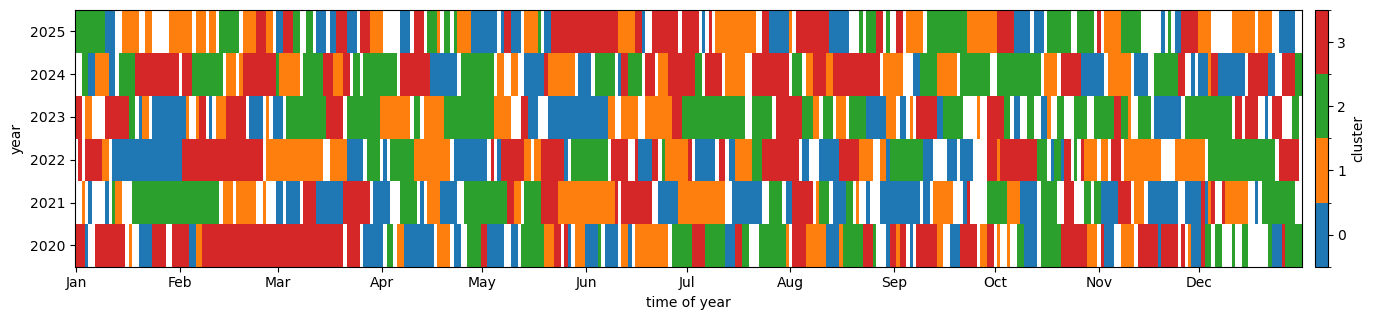

In [82]:
plotOverTimeDaily(labels_deflated_stable, n_clusters=4)

In [43]:
def export_barcode_daily(labels, n_years=6, n_clusters=4, remap=(1, 3, 0, 2), thresh=0.5,
                         win_days=1, prefix="ERA5_z500_labels_daily",
                         tfile="/scratch/ERA5_z500/z500_time.npy"):
    """Daily majority labels (renumbered by remap), uncertain/mixed -> NaN, for gnuplot."""
    t = pd.DatetimeIndex(np.load(tfile)[:len(labels)])
    k = n_clusters
    years = np.arange(t.year.max() - n_years + 1, t.year.max() + 1)
    sel = t.year >= years[0]
    lab = np.minimum(labels[sel], k)                                    # uncertain -> k
    cnt = pd.crosstab(t[sel].normalize(), lab).reindex(columns=range(k + 1), fill_value=0)
    cnt = cnt.rolling(win_days, center=True, min_periods=1).sum()
    best = cnt.values.argmax(1)
    share = cnt.values.max(1) / cnt.values.sum(1)
    rm = np.asarray(remap)
    dlab = np.where((best < k) & (share >= thresh), rm[np.minimum(best, k - 1)], np.nan)

    img = np.full((len(years), 366), np.nan)
    img[cnt.index.year - years[0], cnt.index.dayofyear - 1] = dlab
    with open(f"{prefix}.dat", "w") as fh:                               # day year label
        for i, y in enumerate(years):
            for d in range(366):
                v = img[i, d]
                fh.write(f"{d + 1} {y} {'NaN' if np.isnan(v) else int(v)}\n")
            fh.write("\n")
    print(f"years {years[0]}-{years[-1]}, white days: {np.isnan(dlab).mean():.1%}")

In [93]:
export_barcode_daily(labels_deflated_stable, n_clusters=4)

years 2020-2025, white days: 16.7%


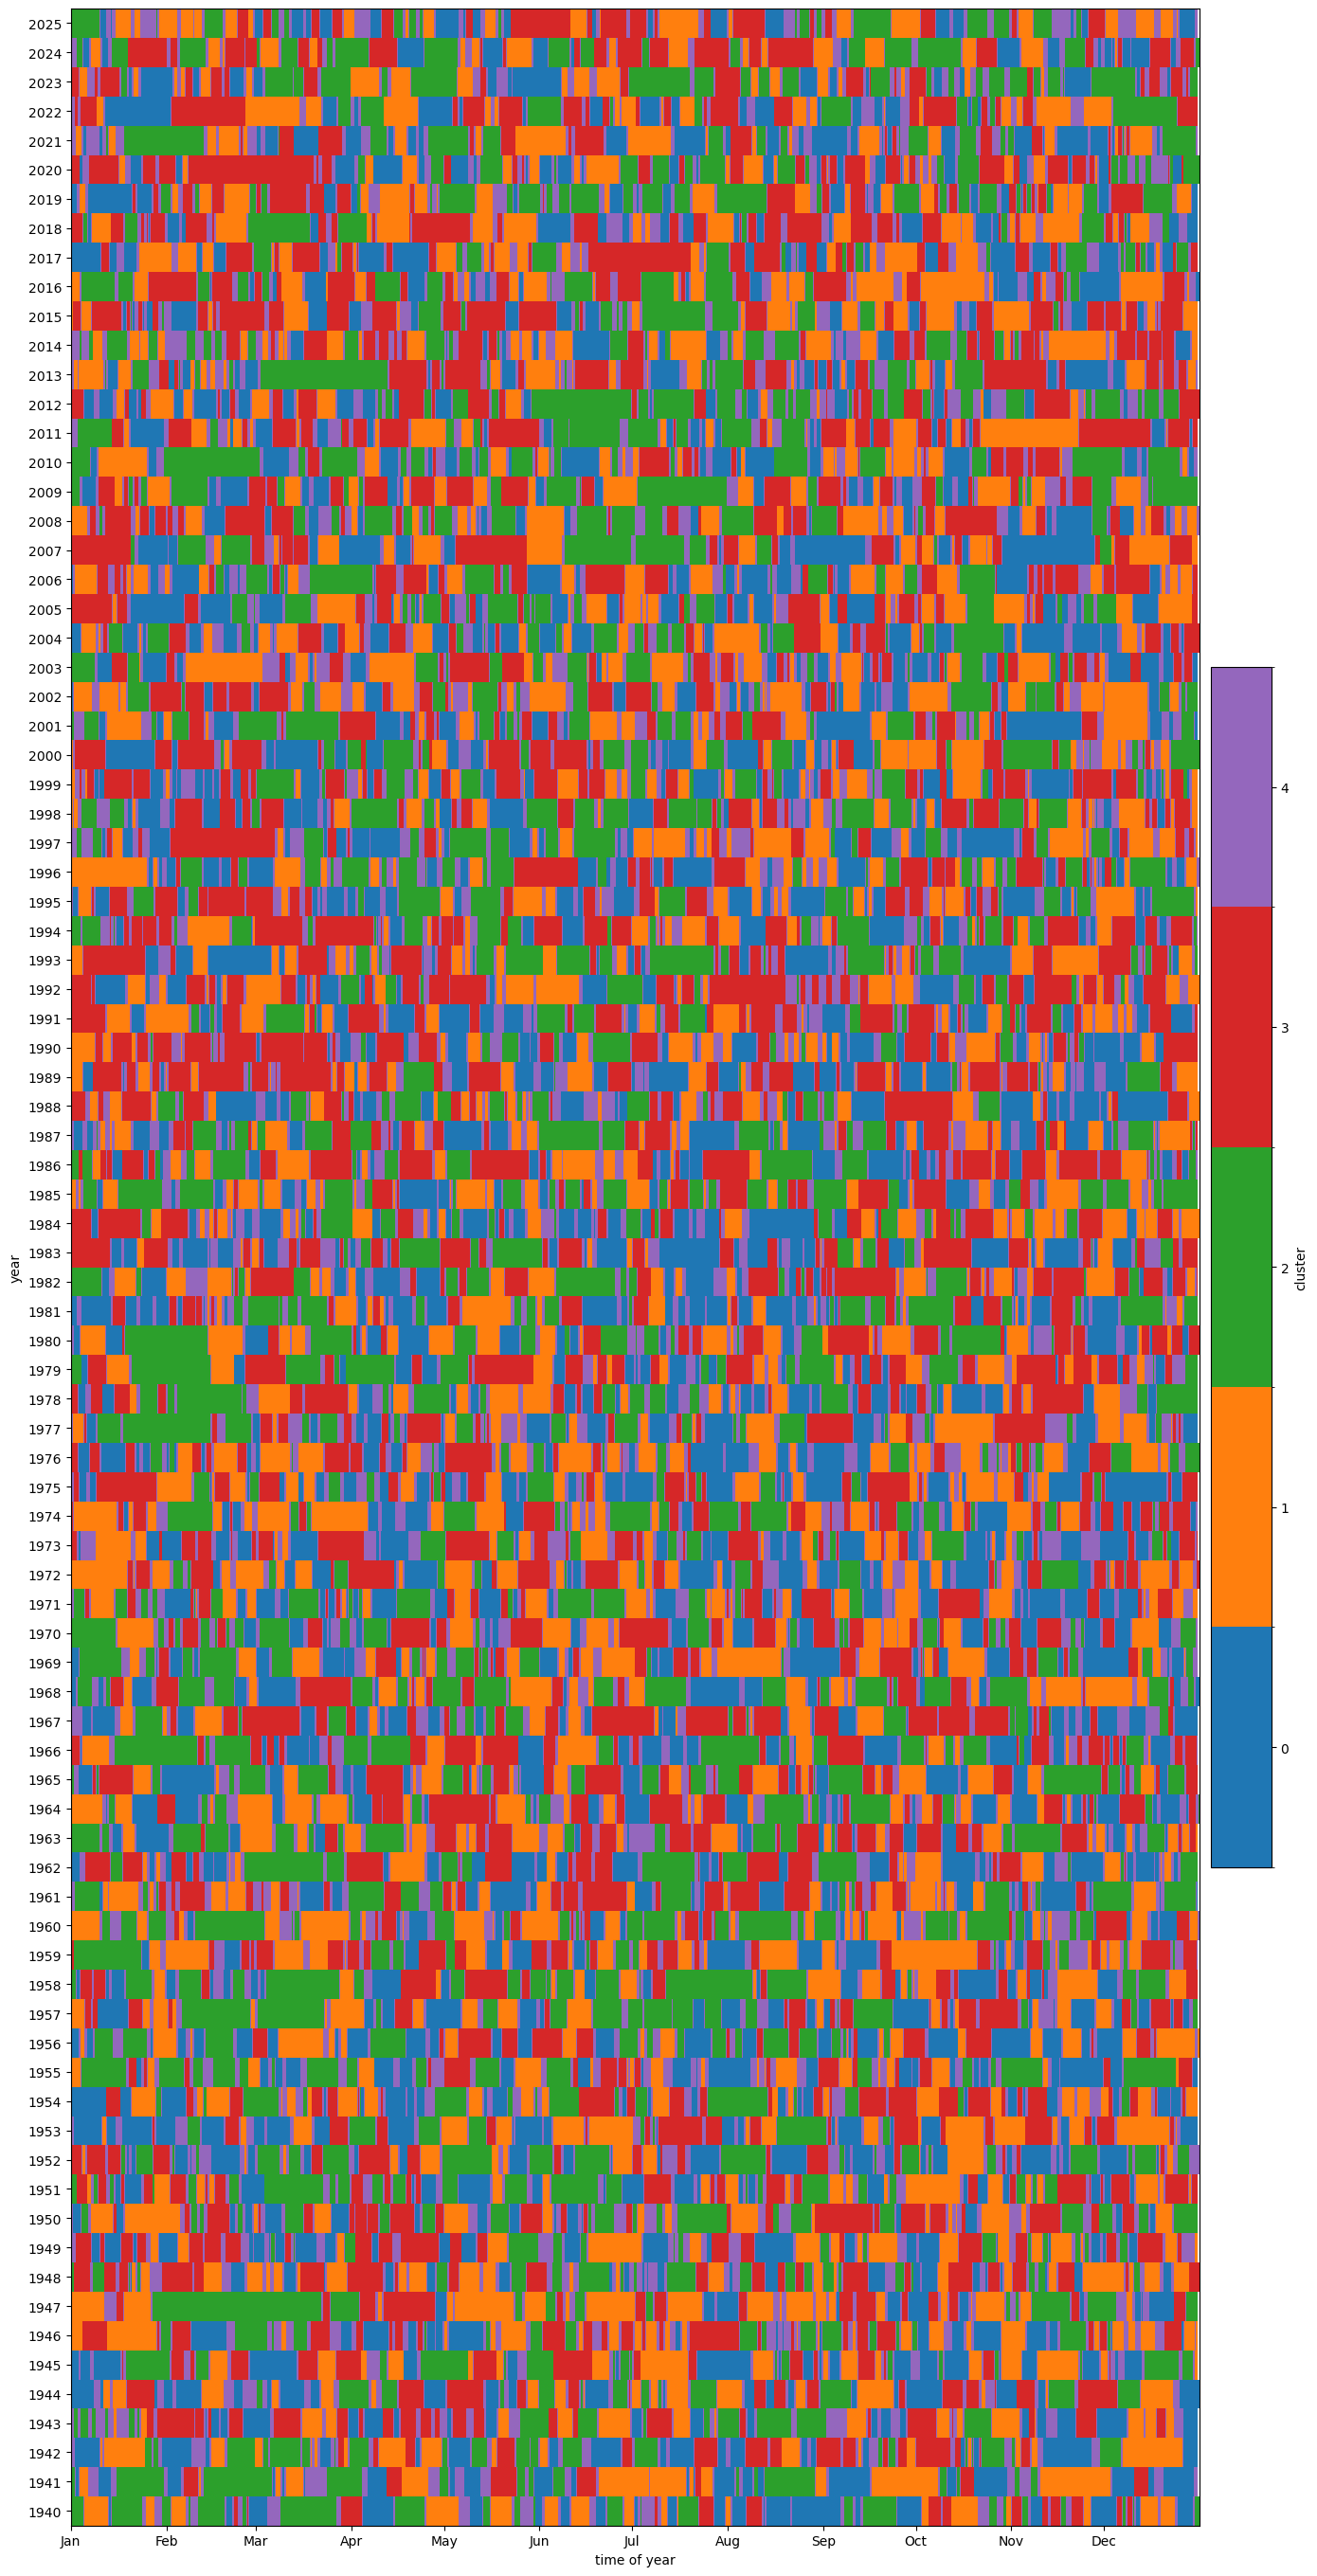

In [81]:
#plotOverTime(labels_deflated_stable)

### TODO: return S in complete workflows below, so I can plot the eigenvalues!


In [44]:
# Generated by claude
def clusterStatistics(labels, with_figures=True):
    k = int(labels.max()) + 1
    t = pd.DatetimeIndex(np.load("/scratch/ERA5_z500/z500_time.npy")[:len(labels)])
    
    # --- run-length encoding: contiguous blocks (episodes) ---
    cut = np.r_[0, np.nonzero(np.diff(labels))[0] + 1, len(labels)]
    ep_lab = labels[cut[:-1]]
    ep_len = np.diff(cut) / 24.0                          # duration in days
    ep_year = t[cut[:-1]].year
    
    # --- statistics per cluster ---
    rows = []
    for c in range(k):
        d = ep_len[ep_lab == c]
        rows.append(dict(cluster=c,
                         share=(labels == c).mean(),
                         episodes=len(d),
                         median_d=np.median(d), mean_d=d.mean(),
                         p90_d=np.percentile(d, 90), max_d=d.max(),
                         frac_lt1d=(d < 1).mean(),                 # flickering episodes
                         time_in_lt1d=d[d < 1].sum() / d.sum(),    # share of time in short episodes
                         years=len(np.unique(ep_year[ep_lab == c]))))
    stats = pd.DataFrame(rows).set_index("cluster")
    print(stats.round(3).to_string())
    print(f"\nall: {len(ep_len)} episodes, median {np.median(ep_len):.2f} d, "
          f"episodes < 1 d: {(ep_len < 1).mean():.1%}, time in them: {ep_len[ep_len < 1].sum() / ep_len.sum():.1%}")

    if not with_figures:
        return
    
    # --- figure 1: duration distribution (log bins) ---
    bins = np.logspace(np.log10(1 / 24), np.log10(ep_len.max()), 40)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist([ep_len[ep_lab == c] for c in range(k)], bins=bins, stacked=True,
            color=plt.cm.tab10.colors[:k], label=[f"cluster {c}" for c in range(k)])
    ax.set_xscale("log"); ax.set_xlabel("episode duration [days]"); ax.set_ylabel("count")
    ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig("episode_durations.png", dpi=150)
    
    # --- figure 2: duration-weighted (where the time is spent) ---
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist([ep_len[ep_lab == c] for c in range(k)], bins=bins, stacked=True,
            weights=[ep_len[ep_lab == c] for c in range(k)],
            color=plt.cm.tab10.colors[:k])
    ax.set_xscale("log"); ax.set_xlabel("episode duration [days]"); ax.set_ylabel("total days")
    plt.tight_layout(); plt.savefig("episode_durations_weighted.png", dpi=150)
    
    # --- figure 3: share of each cluster per year ---
    years = np.arange(t.year.min(), t.year.max() + 1)
    share = np.array([[np.mean(labels[t.year == y] == c) for c in range(k)] for y in years])
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(years, share[:, 0], color=plt.cm.tab10.colors[0], label="cluster 0")
    for c in range(1, k):
        ax.bar(years, share[:, c], bottom=share[:, :c].sum(1),
               color=plt.cm.tab10.colors[c], label=f"cluster {c}")
    ax.set_xlabel("year"); ax.set_ylabel("share of hours")
    ax.legend(fontsize=7, ncol=3, loc="upper right"); plt.tight_layout()
    plt.savefig("cluster_share_per_year.png", dpi=150)

         share  episodes  median_d  mean_d   p90_d   max_d  frac_lt1d  time_in_lt1d  years
cluster                                                                                   
0        0.245      1703     3.292   4.518   9.917  32.042      0.142         0.017     86
1        0.255      1805     3.042   4.430   9.500  46.667      0.133         0.016     86
2        0.247      1847     3.000   4.197   9.350  29.917      0.143         0.019     86
3        0.254      1551     3.333   5.138  11.625  55.292      0.135         0.014     86

all: 6906 episodes, median 3.17 d, episodes < 1 d: 13.8%, time in them: 1.7%


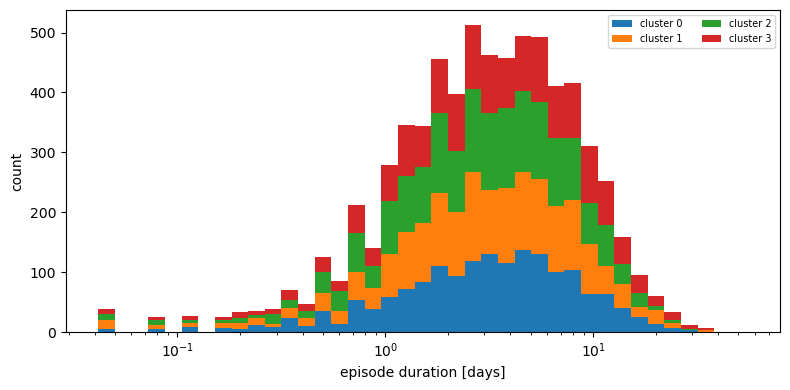

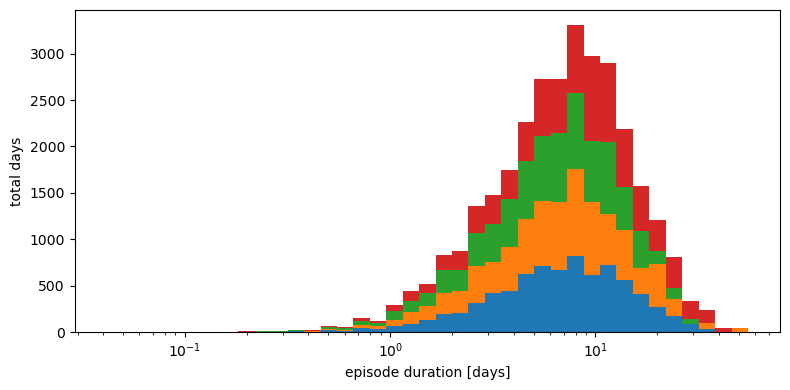

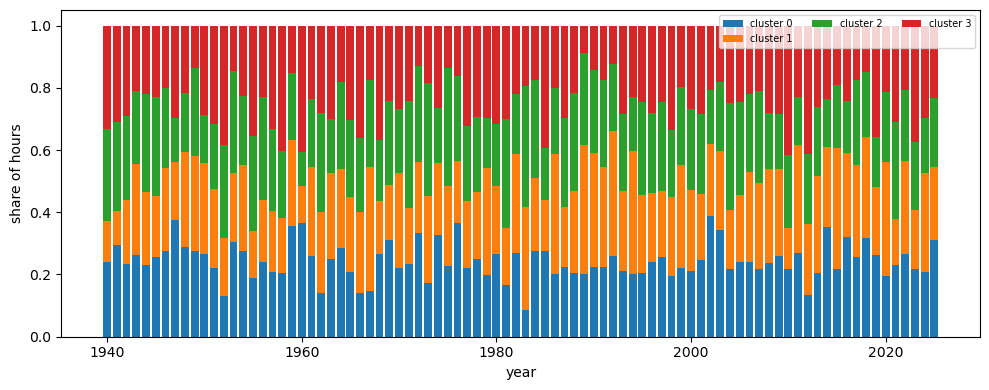

In [84]:
clusterStatistics(labels_deflated)

In [45]:
# Generated by Claude
def plotComposites(Xtt, labels):
    NLAT, NLON = 240, 480
    lat = 90 - 0.25 * np.arange(NLAT)
    lon = -80 + 0.25 * np.arange(NLON)
    
    # labels: (N,) chronological, N must equal the TT time size (753888)
    dims = list(Xtt.dimensions())
    cores = [np.asarray(Xtt.getSubTensor(i)) for i in range(len(dims))]   # (r_l, n, r_r)
    N, k = len(labels), int(labels.max()) + 1
    nt, p = 0, 1
    while p < N:
        p *= dims[nt]; nt += 1
    assert p == N, "time modes must multiply to len(labels)"
    
    # --- 1) time side: contract with normalised cluster indicators ---
    cnt = np.bincount(labels, minlength=k)
    W = np.zeros((N, k)); W[np.arange(N), labels] = 1.0 / cnt[labels]
    L = np.einsum("cr,cmk->rmk", cores[0][0], W.reshape(dims[0], -1, k))   # (r1, N/n1, k)
    for G in cores[1:nt]:
        L = np.einsum("anb,anmk->bmk", G, L.reshape(L.shape[0], G.shape[1], -1, k))
    M = L[:, 0, :]                                                          # (r_nt, k)
    
    # --- 2) feature side: dense maps ---
    F = M.T                                                                 # (k, r)
    for G in cores[nt:]:
        F = np.einsum("k...a,anb->k...nb", F, G)
    F = F[..., 0]                                                           # (k, 2,2,2,2,3,5,480)
    vec = np.moveaxis(F, 0, -1).reshape(-1, k, order="F")                   # (P, k), f = ilat + 240*ilon
    fields = np.stack([vec[:, c].reshape(NLON, NLAT).T for c in range(k)])  # (k, 240, 480)
    
    w = np.sqrt(np.cos(np.deg2rad(lat)))                                    # undo area weighting
    fields = np.where(w[None, :, None] > 1e-6, fields / w[None, :, None], np.nan)
    
    # --- 3) plot ---
    vmax = np.nanpercentile(np.abs(fields), 99)
    levels = np.linspace(-vmax, vmax, 21)
    proj = ccrs.LambertConformal(central_longitude=-20, central_latitude=55, standard_parallels=(40, 70))
    ncol, nrow = 3, int(np.ceil(k / 3))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.2 * nrow), subplot_kw=dict(projection=proj))
    for c, ax in enumerate(np.atleast_1d(axs).flat):
        if c >= k:
            ax.remove(); continue
        cf = ax.contourf(lon, lat, fields[c], levels=levels, cmap="RdBu_r", extend="both",
                         transform=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.5)
        ax.set_extent([-80, 40, 30, 90], crs=ccrs.PlateCarree())
        ax.set_title(f"cluster {c} ({cnt[c] / N:.1%})", fontsize=9)
    fig.colorbar(cf, ax=list(np.atleast_1d(axs).flat[:k]), orientation="horizontal",
             fraction=0.07, pad=0.04, label="mean scaled pattern (arb. units)")
    plt.savefig(f"composites_scaled_k{k}.png", dpi=150, bbox_inches="tight")

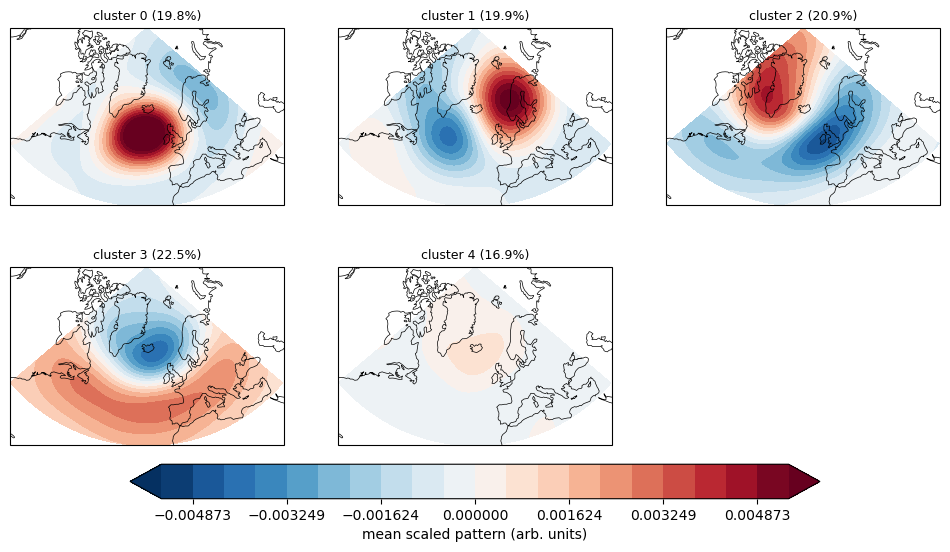

In [86]:
plotComposites(Xtt, labels_deflated_stable)

In [46]:
# Generated by Claude
def compareTTandOrig_for_single_step(Xtt, sample_dims, orig_file="/scratch/ERA5_z500/z500_pattern.npy"):
    NLAT, NLON = 240, 480
    lat = 90 - 0.25 * np.arange(NLAT)
    lon = -80 + 0.25 * np.arange(NLON)
    t = 0                                                     # chronological sample index
    nt = len(sample_dims)
    
    # --- TT: fix the time digits (C-order ravel), contract, expand features ---
    digits = np.unravel_index(t, dims[:nt])                   # (c, b1, ..., b4)
    cores = [Xtt.getSubTensor(i) for i in range(len(Xtt.dimensions()))]
    v = cores[0][0, digits[0], :]
    for G, d in zip(cores[1:nt], digits[1:]):
        v = v @ G[:, d, :]                                    # (r_nt,)
    F = v[None, :]
    for G in cores[nt:]:
        F = np.einsum("k...a,anb->k...nb", F, G)
    vec = np.moveaxis(F[..., 0], 0, -1).reshape(-1, order="F")   # f = ilat + 240*ilon
    x_tt = vec.reshape(NLON, NLAT).T                          # (240, 480)
    
    # --- original row (file order: f = ilat*480 + ilon) ---
    x_ref = np.asarray(np.load(orig_file, mmap_mode="r")[t], np.float64).reshape(NLAT, NLON)
    
    print("rel. error:", np.linalg.norm(x_tt - x_ref) / np.linalg.norm(x_ref))
    
    # --- plot: original | TT | difference ---
    vmax = np.abs(x_ref).max()
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), subplot_kw=dict(projection=ccrs.PlateCarree()))
    for ax, f, title in zip(axs, [x_ref, x_tt, x_tt - x_ref], ["original", "TT", "TT - original"]):
        cf = ax.pcolormesh(lon, lat, f, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                           transform=ccrs.PlateCarree(), shading="auto")
        ax.coastlines(linewidth=0.5)
        ax.set_extent([-80, 40, 30, 90], crs=ccrs.PlateCarree())
        ax.set_title(f"{title} (t={t})", fontsize=9)
    fig.colorbar(cf, ax=list(axs), orientation="horizontal", fraction=0.1, pad=0.08,
                 label="scaled pattern")
    plt.savefig(f"sample_check_t{t}.png", dpi=150, bbox_inches="tight")

rel. error: 0.0852249908931013


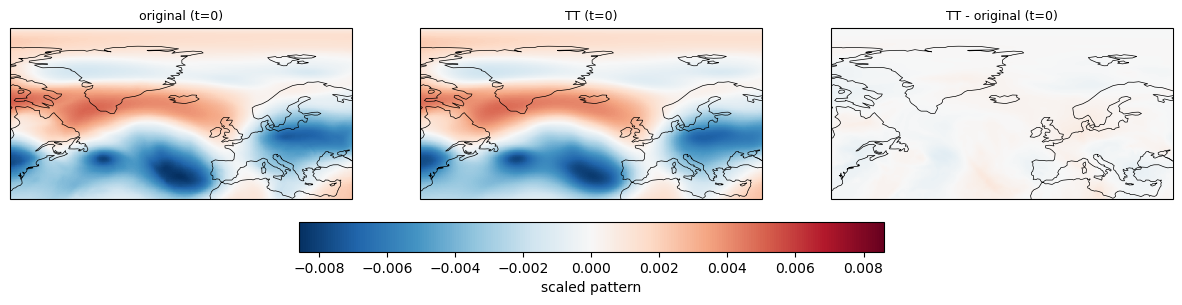

In [88]:
# compares original and 24-hour smoothed variant
compareTTandOrig_for_single_step(Xtt, sample_dims)

Loaded file "Xtt_ERA5_transposed_24h.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1130, 839, 665, 589, 529, 573, 635, 633, 372, 144, 44]
load_tensortrain wtime: 6.883383931592107 memory useage (GB) before/after: 2.17328 2.381264
rel. error: 0.010400446190212112


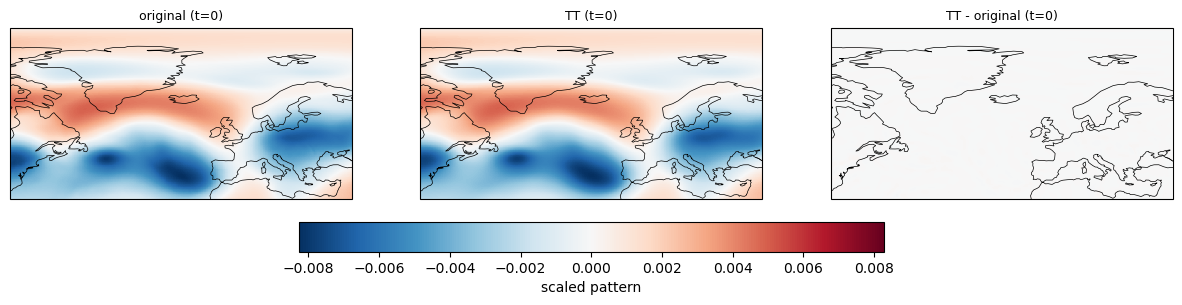

In [23]:
# compares original and TT approx
Xtt_coarse = load_tensortrain('Xtt_ERA5_transposed_24h.npz')
compareTTandOrig_for_single_step(Xtt_coarse, sample_dims, orig_file="/scratch/ERA5_z500/z500_24h_pattern.npy")

In [47]:
def export_sample(Xtt, sample_dims, fname_pattern, tfile, t=None, prefix="ERA5_z500_24h_sample",
                  nx=1600, unweight=True):
    """Original, TT approximation and difference for one time step, LCC images for gnuplot."""
    NLAT, NLON = 240, 480
    lat = 90 - 0.25 * np.arange(NLAT)
    lon = -80 + 0.25 * np.arange(NLON)
    N, nt = int(np.prod(sample_dims)), len(sample_dims)
    t = N - 1 if t is None else t                                   # default: last time step
    date = pd.Timestamp(np.load(tfile)[t]).strftime("%Y-%m-%d %H:%M")

    # --- TT: fix time digits (C-order), contract, expand features (f = ilat + 240*ilon) ---
    cores = [np.asarray(Xtt.getSubTensor(i)) for i in range(len(Xtt.dimensions()))]
    digits = np.unravel_index(t, sample_dims)
    v = cores[0][0, digits[0], :]
    for G, d in zip(cores[1:nt], digits[1:]):
        v = v @ G[:, d, :]
    F = v[None, :]
    for G in cores[nt:]:
        F = np.einsum("k...a,anb->k...nb", F, G)
    x_tt = np.moveaxis(F[..., 0], 0, -1).reshape(-1, order="F").reshape(NLON, NLAT).T

    # --- original row (file order: f = ilat*480 + ilon) ---
    x_ref = np.asarray(np.load(fname_pattern, mmap_mode="r")[t], np.float64).reshape(NLAT, NLON)
    relerr = np.linalg.norm(x_tt - x_ref) / np.linalg.norm(x_ref)

    if unweight:                                                    # undo sqrt(cos(lat)) for display
        w = np.sqrt(np.cos(np.deg2rad(lat)))[:, None]
        x_ref, x_tt = [np.where(w > 1e-6, x / w, np.nan) for x in (x_ref, x_tt)]

    # --- same projected grid as the composites ---
    crs = "+proj=lcc +lat_1=40 +lat_2=70 +lat_0=55 +lon_0=-20 +units=km"
    fwd = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
    inv = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
    n = 200
    bl = np.r_[np.linspace(-80, 40, n), np.full(n, 40), np.linspace(40, -80, n), np.full(n, -80)]
    bb = np.r_[np.full(n, 30), np.linspace(30, 90, n), np.full(n, 90), np.linspace(90, 30, n)]
    bx, by = fwd.transform(bl, bb)
    ny = int(nx * (by.max() - by.min()) / (bx.max() - bx.min()))
    X, Y = np.meshgrid(np.linspace(bx.min(), bx.max(), nx), np.linspace(by.min(), by.max(), ny))
    LO, LA = inv.transform(X, Y)
    inside = (LO >= -80) & (LO <= 40) & (LA >= lat.min()) & (LA <= 90)
    pts = np.c_[LA.ravel(), LO.ravel()]
    for name, f in {"orig": x_ref, "tt": x_tt, "diff": x_tt - x_ref}.items():
        z = RegularGridInterpolator((lat[::-1], lon), f[::-1], bounds_error=False)(pts)
        np.where(inside, z.reshape(ny, nx), np.nan).astype(np.float32).tofile(f"{prefix}_{name}.bin")

    vmax = np.nanpercentile(np.abs(x_ref), 99.5)
    dmax = np.nanpercentile(np.abs(x_tt - x_ref), 99.5)
    with open(f"{prefix}_meta.gp", "w") as fh:                       # gnuplot include file
        fh.write(f"NX = {nx}; NY = {ny}; X0 = {X[0, 0]}; Y0 = {Y[0, 0]}\n")
        fh.write(f"DX = {X[0, 1] - X[0, 0]}; DY = {Y[1, 0] - Y[0, 0]}\n")
        fh.write(f"vmax = {vmax:.4g}; dmax = {dmax:.4g}; relerr = {relerr:.4g}\n")
        fh.write(f"date = '{date}'\n")
    print(f"t = {t} ({date}), rel. error {relerr:.3g}")

In [63]:
export_sample(Xtt_coarse, sample_dims, "/scratch/ERA5_z500/z500_24h_pattern.npy",
              "/scratch/ERA5_z500/z500_time.npy", nx=3200)

t = 753887 (2025-12-31 23:00), rel. error 0.0099


In [48]:
# complete workflow without the deflation
@timer
def computeSpectralClustering(Xtt_file, sigma, similarityTolerance, tciTolerance, tciSweeps, maxRankMiddle=2000, enrichmentRank=300, errorRank=400):
    #pitts_py.clearPerformanceStatistics()
    
    Xtt = load_tensortrain(Xtt_file)
    dims = Xtt.dimensions()
    feature_dims = dims[-7:]
    assert np.prod(feature_dims) == 240*480
    sample_dims = dims[:-7]
    assert sample_dims + feature_dims == dims

    nrm, Xtt_cosineSimilarity = formCosineSimilarity(Xtt, sample_dims, similarityTolerance)
    Xtt_Gaussian = TT_cross_Gaussian(Xtt_cosineSimilarity, nrm, sigma=sigma, tolerance=tciTolerance, nSweeps=tciSweeps, maxRankMiddle=maxRankMiddle, enrichmentRank=enrichmentRank, errorRank=errorRank)
    _nrm = pitts_py.normalize(Xtt_Gaussian, rankTolerance=0.5*tciTolerance, maxRank=2000)
    Xtt_Gaussian.setSubTensor(0, _nrm*Xtt_Gaussian.getSubTensor(0))
    print(Xtt_Gaussian)
    TT_centerSVD(Xtt_Gaussian)
    d_tt = TT_matrixRowSum(Xtt_Gaussian)
    D_tt = TT_symmetricDyadicProduct(d_tt)
    Xtt_Gaussian_normalized = TT_scaleBySqrtInv(Xtt_Gaussian, D_tt, tolerance=tciTolerance, nSweeps=tciSweeps, maxRankMiddle=maxRankMiddle)
    S = TT_centerSVD(Xtt_Gaussian_normalized)

    print('first eigenvalue (1): ', S[0])
    plt.plot(S[1:50], '+')
    labels = computeLabels(Xtt_Gaussian_normalized, n_clusters=4)
    clusterStatistics(labels, with_figures=False)
    return labels, S

Loaded file "Xtt_ERA5_transposed_24h.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1130, 839, 665, 589, 529, 573, 635, 633, 372, 144, 44]
load_tensortrain wtime: 6.880292825400829 memory useage (GB) before/after: 11.969708 12.177708
Cosine similarity (uncompressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1130, 839, 665, 589, 529, 589, 665, 839, 1130]
Cosine similarity (compressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [137, 96, 79, 67, 53, 61, 68, 78, 100]
Cosine similarity norm: 209592.75747016902
formCosineSimilarity wtime: 6.300793711096048 memory useage (GB) before/after: 12.177708 12.175848
TT-cross sweep 0.5: change 1.2517, error estimate 1.40283, sampled error 0.0256968, ranks: 434 395 379 367 353 361 368 378 400
TT-cross sweep 1: change 0.0126

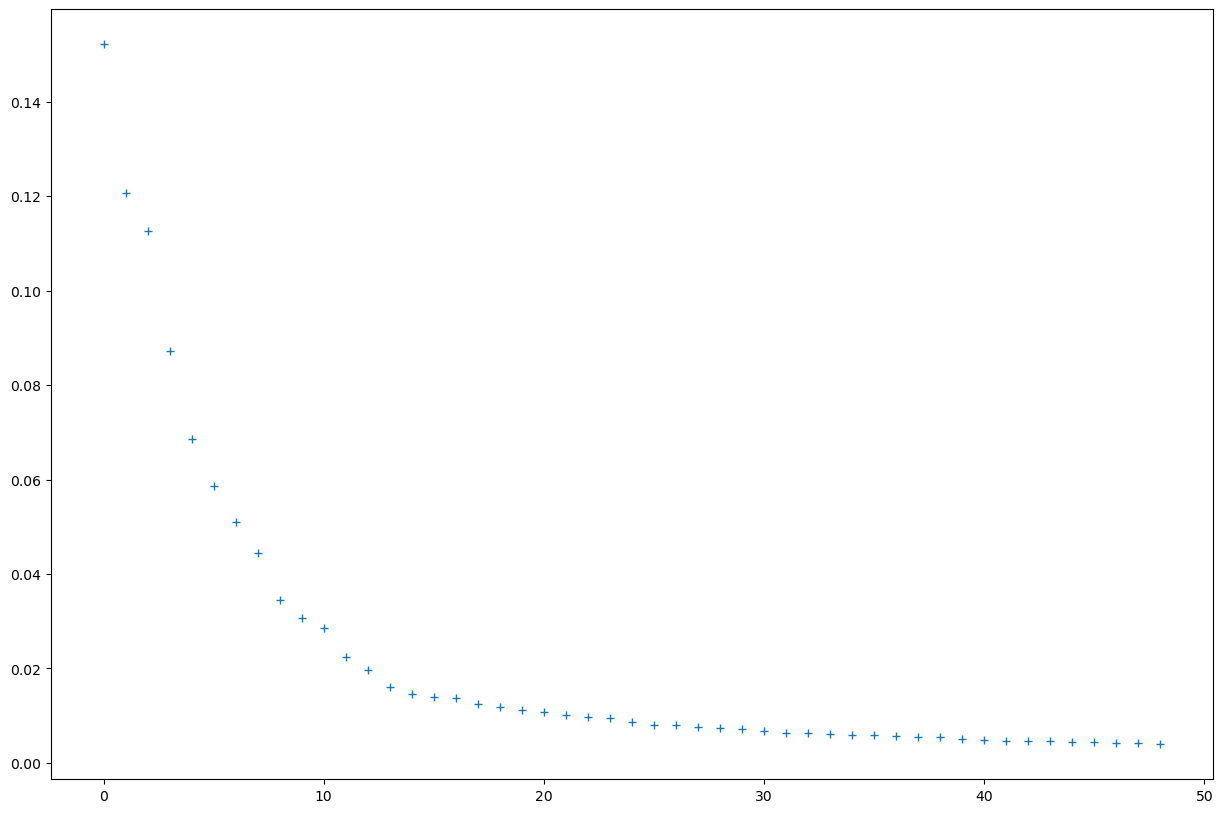

In [90]:
labels_coarse, S_coarse = computeSpectralClustering('Xtt_ERA5_transposed_24h.npz', sigma=1, similarityTolerance=0.01, tciTolerance=0.01, tciSweeps=3)

In [49]:
# complete workflow with the deflation
@timer
def computeSpectralClustering_deflated(Xtt_file, sigma, similarityTolerance, tciTolerance, tciSweeps, maxRankMiddle=2000, enrichmentRank=300, errorRank=400):
    #pitts_py.clearPerformanceStatistics()
    
    Xtt = load_tensortrain(Xtt_file)
    dims = Xtt.dimensions()
    feature_dims = dims[-7:]
    assert np.prod(feature_dims) == 240*480
    sample_dims = dims[:-7]
    assert sample_dims + feature_dims == dims

    nrm, Xtt_cosineSimilarity = formCosineSimilarity(Xtt, sample_dims, similarityTolerance)
    Xtt_Gaussian = TT_cross_Gaussian(Xtt_cosineSimilarity, nrm, sigma=sigma, tolerance=tciTolerance, nSweeps=tciSweeps, maxRankMiddle=maxRankMiddle, enrichmentRank=enrichmentRank, errorRank=errorRank)
    _nrm = pitts_py.normalize(Xtt_Gaussian, rankTolerance=0.5*tciTolerance, maxRank=2000)
    Xtt_Gaussian.setSubTensor(0, _nrm*Xtt_Gaussian.getSubTensor(0))
    print(Xtt_Gaussian)
    TT_centerSVD(Xtt_Gaussian)
    d_tt = TT_matrixRowSum(Xtt_Gaussian)
    D_tt = TT_symmetricDyadicProduct(d_tt)
    vol = TT_vectorRowSum(d_tt)
    Xtt_Gaussian_normalized_deflated = TT_cross_Gaussian_scaled(Xtt_cosineSimilarity, nrm, D_tt, vol, sigma=1, tolerance=tciTolerance*3, nSweeps=tciSweeps, maxRankMiddle=maxRankMiddle, enrichmentRank=enrichmentRank, errorRank=errorRank)
    S = TT_centerSVD(Xtt_Gaussian_normalized_deflated)

    plt.plot(S[:50], '+')
    labels = computeLabels_deflated(Xtt_Gaussian_normalized_deflated, d_tt, n_clusters=4)
    clusterStatistics(labels, with_figures=False)
    return labels, S

Loaded file "Xtt_ERA5_transposed_24h.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1130, 839, 665, 589, 529, 573, 635, 633, 372, 144, 44]
load_tensortrain wtime: 6.81214183755219 memory useage (GB) before/after: 4.069272 4.277256
Cosine similarity (uncompressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1130, 839, 665, 589, 529, 589, 665, 839, 1130]
Cosine similarity (compressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [137, 96, 79, 67, 53, 61, 68, 78, 100]
Cosine similarity norm: 209592.75747016905
formCosineSimilarity wtime: 6.234362483024597 memory useage (GB) before/after: 4.277256 4.685416
TT-cross sweep 0.5: change 1.25244, error estimate 1.41114, sampled error 0.0257421, ranks: 434 395 379 367 353 361 368 378 400
TT-cross sweep 1: change 0.0122958,

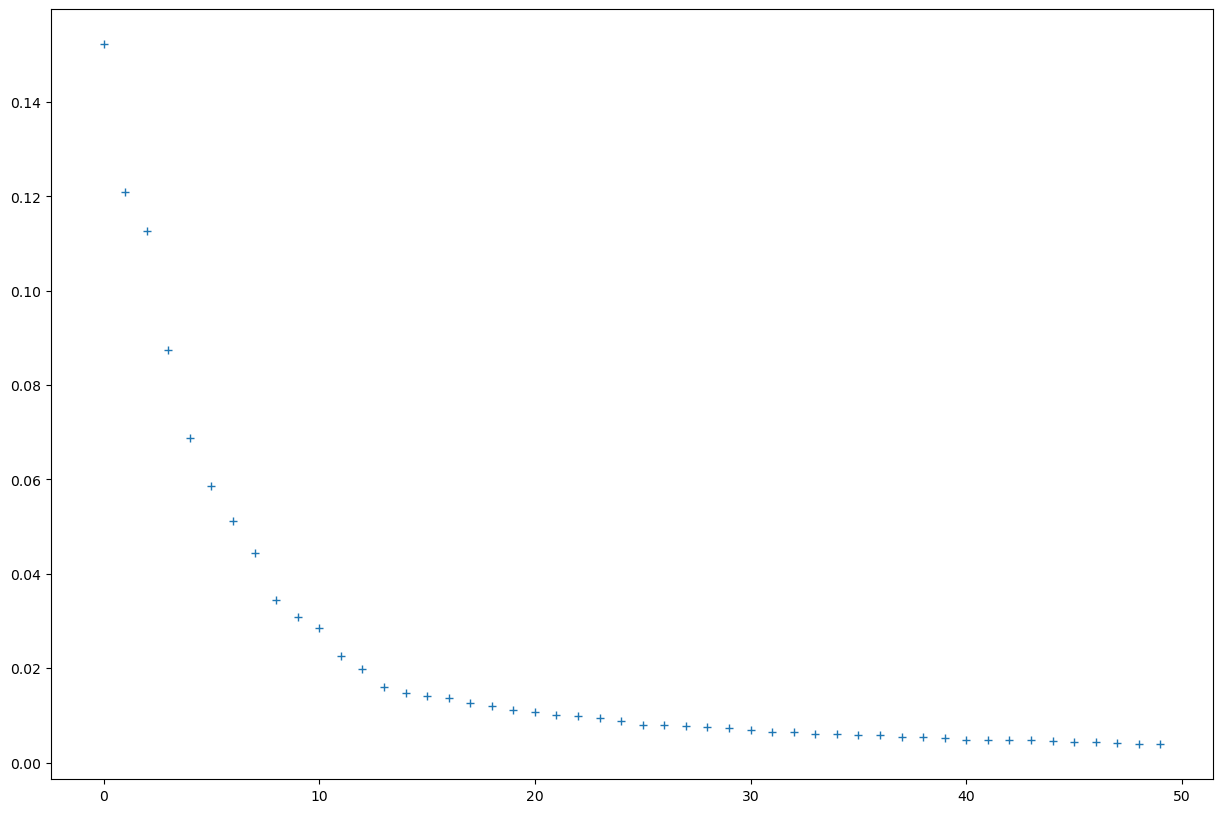

In [58]:
labels_coarse_deflated, S_coarse_deflated = computeSpectralClustering_deflated('Xtt_ERA5_transposed_24h.npz', sigma=1, similarityTolerance=0.01, tciTolerance=0.01, tciSweeps=3)

Loaded file "Xtt_ERA5_transposed_24h_.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1870, 1645, 1450, 1415, 1236, 1246, 1267, 1318, 873, 444, 157]
load_tensortrain wtime: 12.326186303049326 memory useage (GB) before/after: 11.971444 12.315628
Cosine similarity (uncompressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1870, 1645, 1450, 1415, 1236, 1415, 1450, 1645, 1870]
Cosine similarity (compressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [394, 266, 206, 174, 123, 160, 181, 224, 295]
Cosine similarity norm: 209606.27410165768
formCosineSimilarity wtime: 20.03483610600233 memory useage (GB) before/after: 12.315628 12.466648
TT-cross sweep 0.5: change 1.27526, error estimate 1.71861, sampled error 0.0128149, ranks: 858 753 697 670 623 660 681 724 795
TT-cro

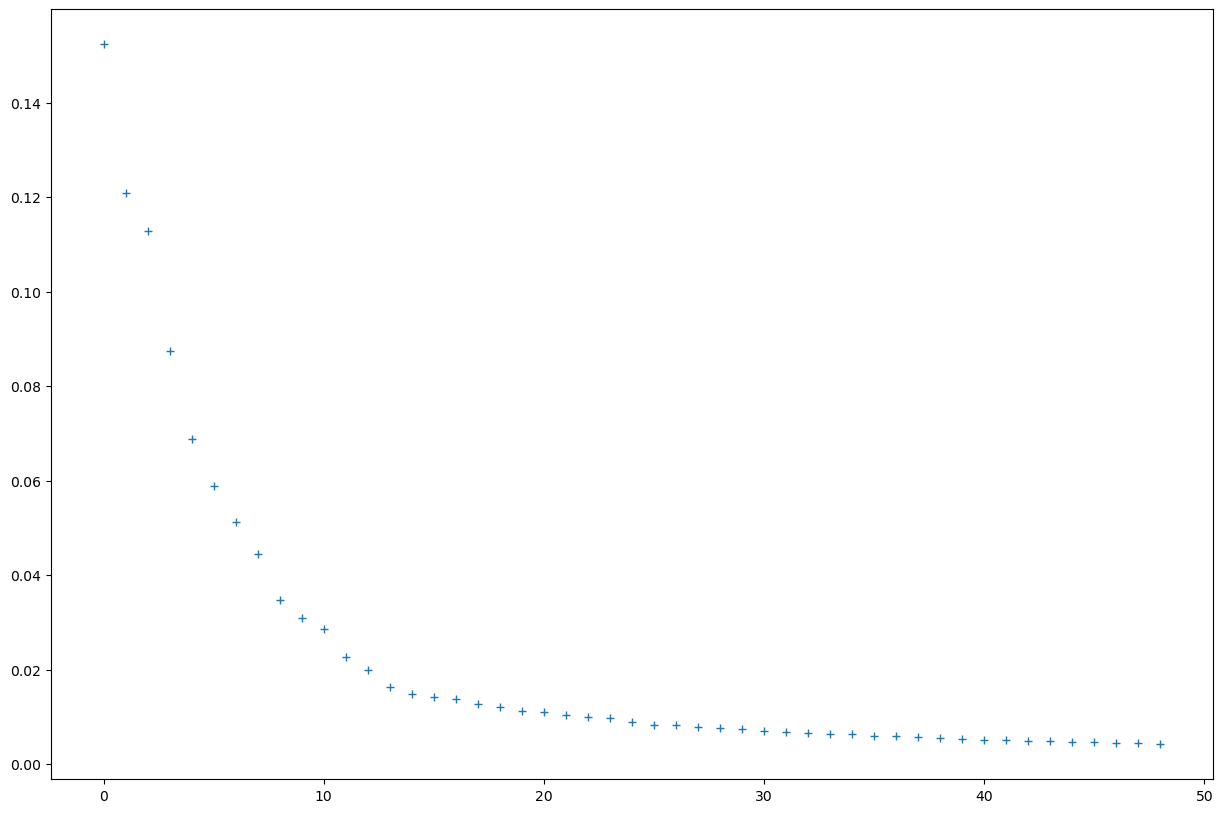

In [96]:
# for timings:
labels_fine, S_fine = computeSpectralClustering('Xtt_ERA5_transposed_24h_.npz', sigma=1, similarityTolerance=0.001, tciTolerance=0.005, tciSweeps=4, enrichmentRank=500, errorRank=1000)

Loaded file "Xtt_ERA5_transposed_24h_.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1870, 1645, 1450, 1415, 1236, 1246, 1267, 1318, 873, 444, 157]
load_tensortrain wtime: 12.760872902348638 memory useage (GB) before/after: 11.967432 12.31162
Cosine similarity (uncompressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1870, 1645, 1450, 1415, 1236, 1415, 1450, 1645, 1870]
Cosine similarity (compressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [394, 266, 206, 174, 123, 160, 181, 224, 295]
Cosine similarity norm: 209606.27410165773
formCosineSimilarity wtime: 21.829118978232145 memory useage (GB) before/after: 12.31162 12.565548
TT-cross sweep 0.5: change 1.27539, error estimate 1.61491, sampled error 0.0135377, ranks: 858 753 697 670 623 660 681 724 795
TT-cros

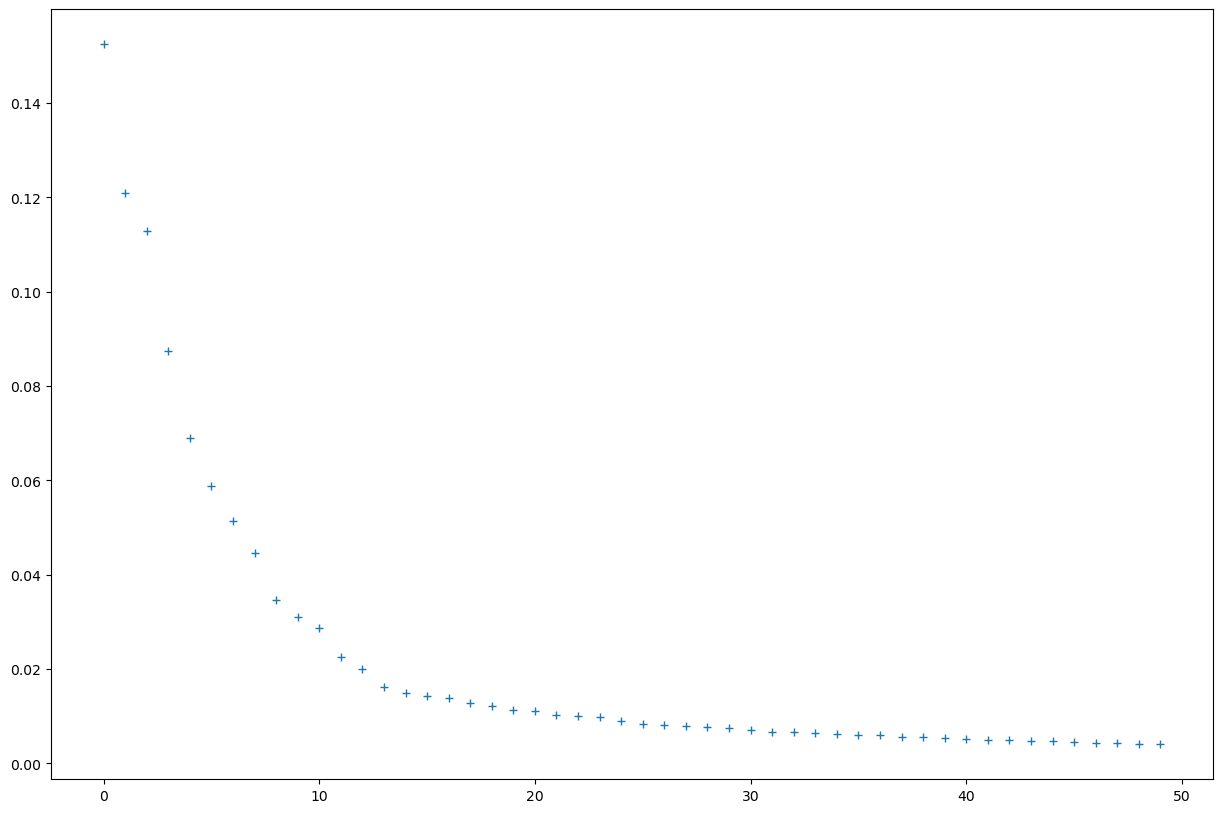

In [97]:
# for timings:
labels_fine_deflated, S_fine_deflated = computeSpectralClustering_deflated('Xtt_ERA5_transposed_24h_.npz', sigma=1, similarityTolerance=0.001, tciTolerance=0.005, tciSweeps=4, enrichmentRank=500, errorRank=1000)

In [50]:
def label_changes(lab, ref_stable, ref_raw, k):
    """lab: labels of an approximation; ref_stable: reference with k = uncertain;
    ref_raw: reference labels before marking uncertain."""
    conf = ref_stable < k
    cm = confusion_matrix(ref_stable[conf], lab[conf], labels=range(k))
    r, c = linear_sum_assignment(-cm)                    # align numbering on confident set
    perm = np.empty(k, dtype=int); perm[c] = r
    lab_m = perm[lab]
    chg = lab_m != ref_raw
    print(f"  changed overall: {chg.sum():8d} ({chg.mean():.2%}), "
          f"confident: {chg[conf].sum()}, uncertain: {chg[~conf].sum()} ({chg[~conf].mean():.2%})")
    print("  uncertain set, reference (rows) -> approximation (cols):")
    print(confusion_matrix(ref_raw[~conf], lab_m[~conf], labels=range(k)))
    return chg

print(f"confident reference steps: {conf.mean():.1%}")
for name, lab in {"fine": labels, "fine2": labels_fine, "fine,deflated": labels_deflated, "fine,deflated2": labels_fine_deflated, "coarse": labels_coarse,
                  "coarse,deflated": labels_coarse_deflated}.items():
    acc, rec, ari, _ = recovery(lab, labels_deflated_stable, conf, 4)
    print(f"{name}: recovered {acc:.3f}, ARI {ari:.3f}, per-cluster recall {np.round(rec, 3)}")
    label_changes(lab, labels_deflated_stable, major, 4)

NameError: name 'conf' is not defined

relative difference of the first non-trivial eigenvalue:  fine  -  4.963114999983385e-05
relative difference of the first non-trivial eigenvalue:  fine2  -  8.884378331474528e-05
relative difference of the first non-trivial eigenvalue:  fine,deflated  -  0.0
relative difference of the first non-trivial eigenvalue:  fine,deflated2  -  1.894545140880783e-05
relative difference of the first non-trivial eigenvalue:  coarse  -  0.00038322110593845695
relative difference of the first non-trivial eigenvalue:  coarse,deflated  -  0.0002546067591532102


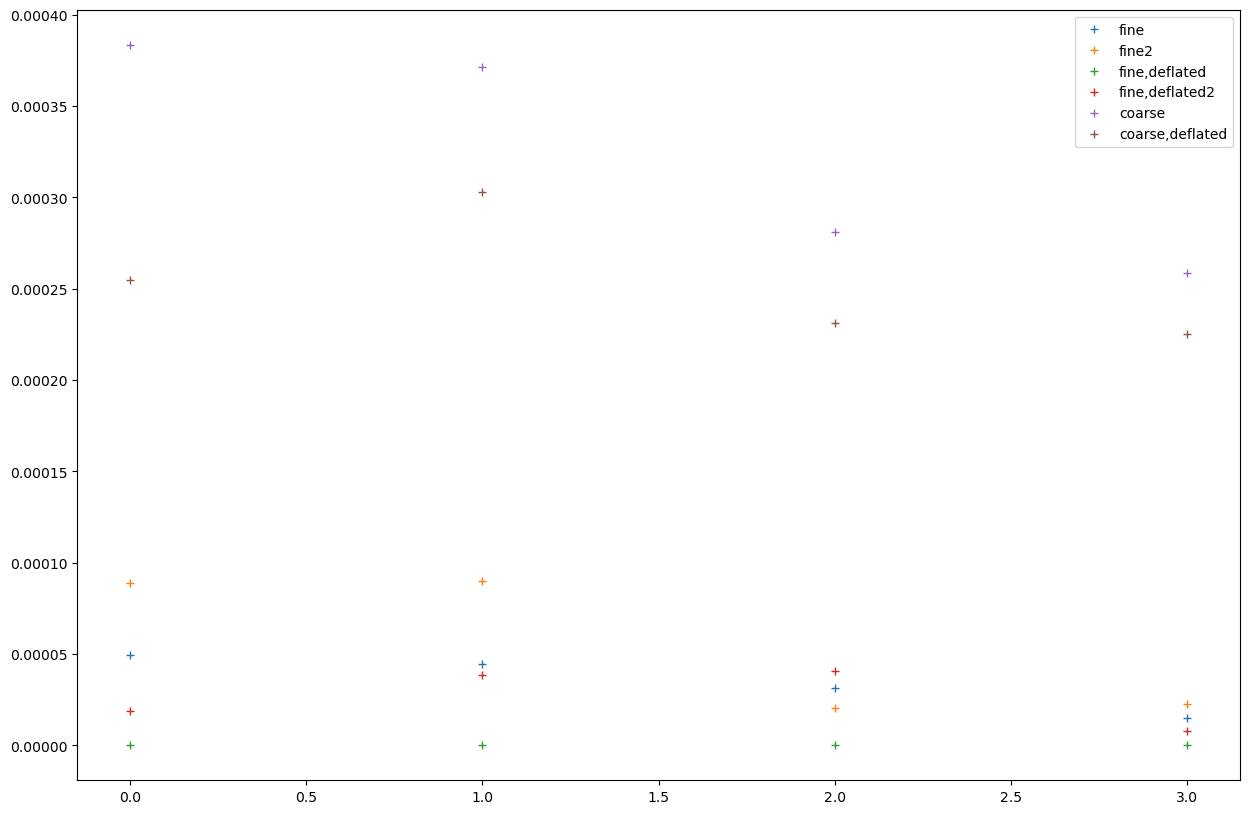

In [165]:
for name, cur_S in {"fine": S, "fine2": S_fine, "fine,deflated": np.concatenate(([1,],S_deflated)), "fine,deflated2": np.concatenate(([1,],S_fine_deflated)), "coarse": S_coarse,
                  "coarse,deflated": np.concatenate(([1,],S_coarse_deflated))}.items():
    ref = 1 - S_deflated[:4]
    cur = 1 - cur_S[1:5]
    plt.plot(np.abs(cur-ref)/np.abs(ref), '+', label=name)
    print('relative difference of the first non-trivial eigenvalue: ', name, " - ", np.linalg.norm(cur_S[1] - S_deflated[0])/np.abs(1-S_deflated[0]))
plt.legend()

In [166]:
def exportS():
    variants = {"fine": S,
                "fine, deflated": np.concatenate(([1], S_deflated)),
                "coarse": S_coarse,
                "coarse, deflated": np.concatenate(([1], S_coarse_deflated))}
    n = 20
    idx = np.arange(2, n + 1)                                     # eigenvalue number (1 = trivial)
    cols = [1 - np.asarray(v)[1:n] for v in variants.values()]    # lambda_i of L_sym
    header = "i " + " ".join(f'"{nm}"' for nm in variants)
    np.savetxt("ERA5_z500_eigenvalues.dat", np.c_[idx, np.column_stack(cols)],
               fmt="%.6g", header=header, comments="")
exportS()

In [51]:
# Generated by Claude
def computeCompositesFromOriginalData(labels):
    np.save("/scratch/ERA5_z500/labels_24h.npy", labels)
    NLAT, NLON = 240, 480
    X = np.load("/scratch/ERA5_z500/z500_anom_24h.npy")      # (N_file, P) float32, ~350 GB
    N = len(labels)                                          # labels chronological
    k = int(labels.max()) + 1                                # includes 'uncertain' if present
    cnt = np.bincount(labels, minlength=k)
    
    S = np.zeros((k, X.shape[1]))
    B = 16384
    for i in range(0, N, B):
        l = labels[i:i + B]
        A = np.zeros((k, len(l)), dtype=np.float32)
        A[l, np.arange(len(l))] = 1.0                        # cluster indicators of this block
        S += A @ X[i:i + B]                                  # (k, P), accumulated in float64
    
    comp = (S / cnt[:, None]).reshape(k, NLAT, NLON)         # composites in gpm, file order (lat, lon)
    np.save("/scratch/ERA5_z500/composites_24h_gpm.npy", comp)
    print("range [gpm]:", np.nanmin(comp), np.nanmax(comp))

In [100]:
#computeCompositesFromOriginalData(labels_deflated_stable)

In [52]:
# Generated by Claude
def export_gnuplot(comp, cnt, prefix="comp", proj="lcc", nx=600):
    """comp: (k, 240, 480) composites (lat 90..30.25, lon -80..39.75); cnt: members per cluster."""
    NLAT, NLON = comp.shape[1:]
    lat = 90 - 0.25 * np.arange(NLAT)
    lon = -80 + 0.25 * np.arange(NLON)
    k = len(comp)
    fwd = None
    if proj == "lcc":
        from pyproj import Transformer
        from scipy.interpolate import RegularGridInterpolator
        crs = "+proj=lcc +lat_1=40 +lat_2=70 +lat_0=55 +lon_0=-20 +units=km"
        fwd = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
        inv = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
        n = 200                                                   # domain outline
        bl = np.r_[np.linspace(-80, 40, n), np.full(n, 40), np.linspace(40, -80, n), np.full(n, -80)]
        bb = np.r_[np.full(n, 30), np.linspace(30, 90, n), np.full(n, 90), np.linspace(90, 30, n)]
        bx, by = fwd.transform(bl, bb)
        np.savetxt(f"{prefix}_boundary.dat", np.c_[bx, by], fmt="%.4g")
        ny = int(nx * (by.max() - by.min()) / (bx.max() - bx.min()))
        X, Y = np.meshgrid(np.linspace(bx.min(), bx.max(), nx), np.linspace(by.min(), by.max(), ny))
        LON, LAT = inv.transform(X, Y)
        inside = (LON >= -80) & (LON <= 40) & (LAT >= 30) & (LAT <= 90)
        pts = np.c_[LAT.ravel(), LON.ravel()]
        fields = [np.where(inside, RegularGridInterpolator((lat[::-1], lon), comp[c][::-1],
                           bounds_error=False)(pts).reshape(ny, nx), np.nan) for c in range(k)]
    else:                                                         # plate carree
        X, Y = np.meshgrid(lon, lat)
        fields = list(comp)

    for c in range(k):                                            # x y z, blank line per row
        with open(f"{prefix}_{c}.dat", "w") as fh:
            for j in range(X.shape[0]):
                np.savetxt(fh, np.c_[X[j], Y[j], fields[c][j]], fmt="%.4g")
                fh.write("\n")

    import cartopy.io.shapereader as shpreader                    # coastlines, clipped
    from shapely.geometry import box
    dom = box(-80, 30, 40, 90)
    with open(f"{prefix}_coast.dat", "w") as fh:
        for geom in shpreader.Reader(shpreader.natural_earth("50m", "physical", "coastline")).geometries():
            g = geom.intersection(dom)
            for line in getattr(g, "geoms", [g]):
                if line.is_empty or not hasattr(line, "coords"):
                    continue
                cx, cy = np.array(line.coords).T
                if fwd is not None:
                    cx, cy = fwd.transform(cx, cy)
                np.savetxt(fh, np.c_[cx, cy], fmt="%.4g"); fh.write("\n")

    np.savetxt(f"{prefix}_meta.dat", np.c_[np.arange(k), cnt / cnt.sum()], fmt="%d %.4f")

In [53]:
def export_gnuplot(comp, cnt, n_total, prefix="ERA5_z500_composites_24h", nx=1600):
    """comp: (k,240,480) anomaly composites [gpm]; cnt: members per cluster."""
    lat = 90 - 0.25 * np.arange(comp.shape[1])
    lon = -80 + 0.25 * np.arange(comp.shape[2])
    crs = "+proj=lcc +lat_1=40 +lat_2=70 +lat_0=55 +lon_0=-20 +units=km"
    fwd = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
    inv = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)

    # domain outline and projected grid (rows: y ascending, x fastest)
    n = 200
    bl = np.r_[np.linspace(-80, 40, n), np.full(n, 40), np.linspace(40, -80, n), np.full(n, -80)]
    bb = np.r_[np.full(n, 30), np.linspace(30, 90, n), np.full(n, 90), np.linspace(90, 30, n)]
    bx, by = fwd.transform(bl, bb)
    np.savetxt(f"{prefix}_boundary.dat", np.c_[bx, by], fmt="%.6g")
    ny = int(nx * (by.max() - by.min()) / (bx.max() - bx.min()))
    X, Y = np.meshgrid(np.linspace(bx.min(), bx.max(), nx), np.linspace(by.min(), by.max(), ny))
    LO, LA = inv.transform(X, Y)
    inside = (LO >= -80) & (LO <= 40) & (LA >= lat.min()) & (LA <= 90)
    np.savetxt(f"{prefix}_grid.dat", [[nx, ny, X[0, 0], Y[0, 0], X[0, 1] - X[0, 0], Y[1, 0] - Y[0, 0]]],
               fmt="%.10g")                                   # nx ny x0 y0 dx dy

    # anomaly fields: upsampled float32 binary images
    pts = np.c_[LA.ravel(), LO.ravel()]
    for c in range(len(comp)):
        f = RegularGridInterpolator((lat[::-1], lon), comp[c][::-1], bounds_error=False)
        z = np.where(inside, f(pts).reshape(ny, nx), np.nan)
        z.astype(np.float32).tofile(f"{prefix}_{c}.bin")

    # coastlines (Natural Earth), clipped and projected
    dom = box(-80, lat.min(), 40, 90)
    with open(f"{prefix}_coast.dat", "w") as fh:
        for geom in shpreader.Reader(shpreader.natural_earth("110m", "physical", "coastline")).geometries():
            g = geom.intersection(dom)#.simplify(0.01)
            for l in getattr(g, "geoms", [g]):
                if l.is_empty or not hasattr(l, "coords"):
                    continue
                x, y = np.array(l.coords).T
                np.savetxt(fh, np.c_[fwd.transform(x, y)], fmt="%.6g"); fh.write("\n")

    np.savetxt(f"{prefix}_meta.dat", np.c_[np.arange(len(comp)), cnt / n_total], fmt="%d %.4f")

In [103]:
#cnt = np.bincount(labels_deflated_stable, minlength=4)
#comp = np.load("/scratch/ERA5_z500/composites_24h_gpm.npy")
#export_gnuplot(comp[:4], cnt[:4], len(labels_deflated_stable), prefix="ERA5_z500_composites_24h", nx=3200)

In [54]:
def plot_embedding(Y, labels, dims=(1, 2), names=None, n=30000, normalize=False,
                   fname="embedding_2d.png"):
    """Scatter of a random sample of rows of Y in the plane of columns dims, coloured by label.
    Only labels 0..len(names)-1 are plotted."""
    names = names or [f"cluster {c}" for c in range(int(labels.max()) + 1)]
    cols = ["#d6604d", "#4393c3", "#1b7837", "#762a83", "#e08214", "#35978f"]
    if normalize:                                          # what NJW k-means sees
        Y = Y / np.linalg.norm(Y, axis=1, keepdims=True)
    keep = np.nonzero(labels < len(names))[0]
    idx = np.random.default_rng(0).choice(keep, min(n, len(keep)), replace=False)

    fig, ax = plt.subplots(figsize=(6, 5))
    for c, nm in enumerate(names):
        m = idx[labels[idx] == c]
        ax.scatter(Y[m, dims[0]], Y[m, dims[1]], s=2, alpha=0.4, color=cols[c % len(cols)],
                   label=nm, rasterized=True)
    ax.set_xlabel(f"column {dims[0]}"); ax.set_ylabel(f"column {dims[1]}")
    ax.legend(markerscale=5, fontsize=8)
    plt.tight_layout(); plt.savefig(fname, dpi=150)
    return fig, ax

(<Figure size 600x500 with 1 Axes>,
 <Axes: xlabel='column 1', ylabel='column 2'>)

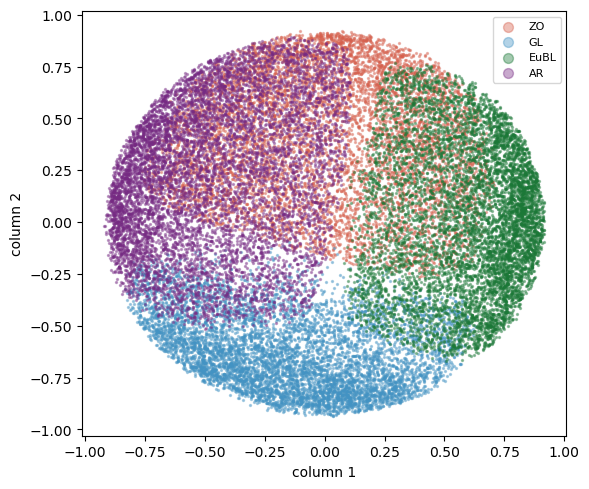

In [105]:
# eigenvector embedding
plot_embedding(Y, labels_deflated_stable, dims=(1,2), names=('ZO', 'GL', 'EuBL', 'AR'))

In [55]:
# for pca embedding
def extractSampleSingularVectors(Xtt, sample_dims, feature_dims, n, tolerance=1.e-4):
    # ensure sufficient orthogonality
    pitts_py.internal.ensureLeftOrtho_range(Xtt, 0, len(sample_dims))
    pitts_py.internal.ensureRightOrtho_range(Xtt, len(sample_dims), len(sample_dims + feature_dims)-1)

    subTr = Xtt.getSubTensor(len(sample_dims))
    # print('old shape', subTr.shape)
    U, S, Vt = np.linalg.svd(subTr.reshape((subTr.shape[0], subTr.shape[1]*subTr.shape[2]), order='F'), full_matrices=False)
    subTl = Xtt.getSubTensor(len(sample_dims)-1)
    subTl = np.einsum('ijk,kl->ijl', subTl, U)
    subTr = (np.diag(S) @ Vt).reshape((S.shape[0], subTr.shape[1], subTr.shape[2]), order='F')
    # print('new shape', subTr.shape)
    Xtt.setSubTensor(len(sample_dims)-1, subTl)
    Xtt.setSubTensor(len(sample_dims), subTr)
    
    subTs = list(reversed([Xtt.getSubTensor(i).T for i in range(len(sample_dims))]))
    subTs[0] = subTs[0][:n,:,:]
    I = np.eye(n, n, dtype=np.float32).reshape((1,n,n), order='C', copy=False)
    subTs = [I] + subTs
    tt = pitts_py.TensorTrain_double([subT.shape[1] for subT in subTs])
    tt.setTTranks([subT.shape[2] for subT in subTs[:-1]])
    for i, subT in enumerate(subTs):
        tt.setSubTensor(i, subT)
    print('top samples singular vectors (uncompressed):', tt)
    z = pitts_py.toDense(tt).reshape((n, np.prod(sample_dims)), order='F').T
    return z, S

In [107]:
X_pca3, S_pca3 = extractSampleSingularVectors(Xtt, sample_dims, feature_dims, 3)

top samples singular vectors (uncompressed): PITTS::TensorTraindouble
        with dimensions = [3, 2, 2, 2, 2, 47118]
             ranks      = [3, 1201, 1307, 1541, 1867]


(<Figure size 600x500 with 1 Axes>,
 <Axes: xlabel='column 0', ylabel='column 1'>)

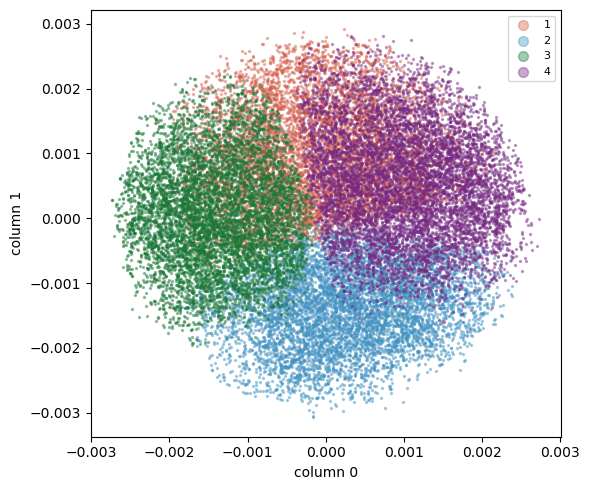

In [108]:
# PCA embedding
plot_embedding(X_pca3, labels_deflated_stable, dims=(0,1), names=('1', '2', '3', '4'))

In [56]:
def export_pca_data(pcs, s, labels, names, prefix="ERA5_z500_embedding_pca", nper=1000):
    """pcs: (N, 2) PC coordinates (U[:, :2] * s[:2]); s: all singular values of the bond."""
    rng = np.random.default_rng(0)
    for c, nm in enumerate(names):
        m = np.nonzero(labels == c)[0]
        idx = rng.choice(m, min(nper, len(m)), replace=False)
        np.savetxt(f"{prefix}_{nm}.dat", pcs[idx], fmt="%.4g")
    np.savetxt(f"{prefix}_meta.dat", [100 * s[:2]**2 / np.sum(s**2)], fmt="%.1f")

In [110]:
export_pca_data(X_pca3[:,:2], S_pca3, labels_deflated_stable, ["AR", "EuBL", "GL", "ZO"])

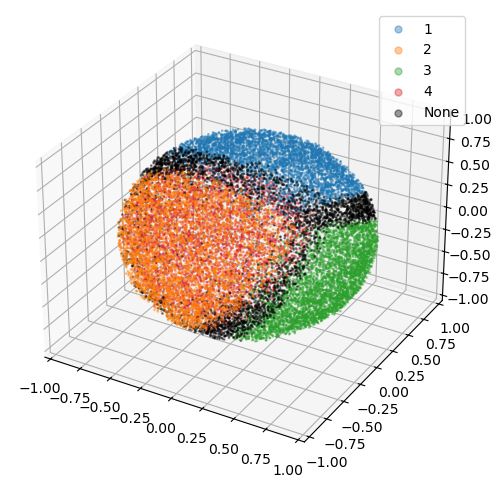

In [111]:
V = Y
Vn = V[:, :4] / np.linalg.norm(V[:, :4], axis=1, keepdims=True)
idx = np.random.default_rng(0).choice(np.nonzero(labels_deflated_stable < 5)[0], 20000, replace=False)
ax = plt.figure(figsize=(6, 6)).add_subplot(projection="3d")
for c, nm in enumerate(["1", "2", "3", "4", "None"]):
   m = idx[labels_deflated_stable[idx] == c]
   if c == 4:
      ax.scatter(Vn[m, 1], Vn[m, 2], Vn[m, 3], s=1, alpha=0.4, label=nm, color='Black')
   else:
      ax.scatter(Vn[m, 1], Vn[m, 2], Vn[m, 3], s=1, alpha=0.4, label=nm)
ax.legend(markerscale=5)

In [112]:
# best embedding separating the clusters (LDA) using the eigenvectors
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
def plot_lda(Y, labels, names, n=30000, normalize=True, fname="embedding_lda.png"):
    """2D LDA projection of the embedding Y (e.g. V[:, :k], col 0 trivial),
    only labels 0..len(names)-1."""
    if normalize:
        Y = Y / np.linalg.norm(Y, axis=1, keepdims=True)
    Y = Y[:, 1:]                                           # drop trivial direction
    keep = np.nonzero(labels < len(names))[0]
    idx = np.random.default_rng(0).choice(keep, min(n, len(keep)), replace=False)
    #lda = PCA(n_components=2).fit(Y[idx])
    lda = LinearDiscriminantAnalysis(n_components=2).fit(Y[idx], labels[idx])
    Z = lda.transform(Y[idx])

    cols = ["#d6604d", "#4393c3", "#1b7837", "#762a83", "#e08214", "#35978f"]
    fig, ax = plt.subplots(figsize=(6, 5))
    for c, nm in enumerate(names):
        m = labels[idx] == c
        ax.scatter(Z[m, 0], Z[m, 1], s=2, alpha=0.4, color=cols[c % len(cols)], label=nm,
                   rasterized=True)
    ax.set_xlabel(f"LD 1 ({lda.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"LD 2 ({lda.explained_variance_ratio_[1]:.0%})")
    ax.legend(markerscale=5, fontsize=8)
    plt.tight_layout(); plt.savefig(fname, dpi=150)
    return lda

In [113]:
#lda = plot_lda(Y, labels_deflated_stable, ["ZO", "AR", "EuBL", "GL"])

Loaded file "Xtt_ERA5_transposed_24h.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1130, 839, 665, 589, 529, 573, 635, 633, 372, 144, 44]
load_tensortrain wtime: 7.028935419395566 memory useage (GB) before/after: 1.580392 1.78838
Cosine similarity (uncompressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1130, 839, 665, 589, 529, 589, 665, 839, 1130]
Cosine similarity (compressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [137, 96, 79, 67, 53, 61, 68, 78, 100]
Cosine similarity norm: 209592.75747016905
formCosineSimilarity wtime: 6.193525226786733 memory useage (GB) before/after: 1.78838 3.062624
TT-cross sweep 0.5: change 1.2806, error estimate 1.41964, sampled error 0.00880428, ranks: 428 392 376 366 353 361 368 378 400
TT-cross sweep 1: change 0.00470337,

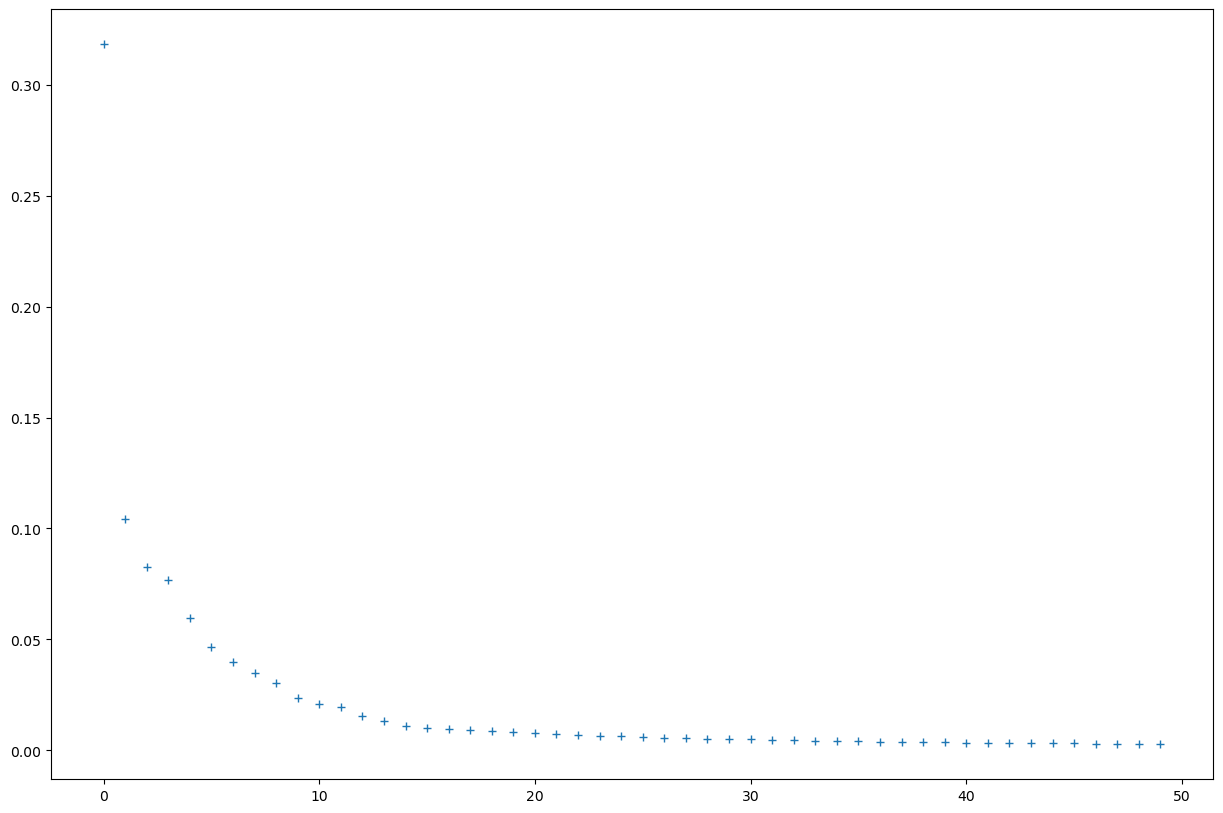

In [57]:
labels_coarse_deflated_sigma1_3, S_coarse_deflated_sigma1_3 = computeSpectralClustering_deflated('Xtt_ERA5_transposed_24h.npz', sigma=1.3, similarityTolerance=0.01, tciTolerance=0.01, tciSweeps=3)

Loaded file "Xtt_ERA5_transposed_24h.npz" to PITTS::TensorTrainfloat
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 3, 5, 480]
             ranks      = [1130, 839, 665, 589, 529, 573, 635, 633, 372, 144, 44]
load_tensortrain wtime: 6.632828509435058 memory useage (GB) before/after: 6.171192 6.379176
Cosine similarity (uncompressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [1130, 839, 665, 589, 529, 589, 665, 839, 1130]
Cosine similarity (compressed): PITTS::TensorTraindouble
        with dimensions = [47118, 2, 2, 2, 2, 2, 2, 2, 2, 47118]
             ranks      = [137, 96, 79, 67, 53, 61, 68, 78, 100]
Cosine similarity norm: 209592.75747016902
formCosineSimilarity wtime: 6.207956161350012 memory useage (GB) before/after: 6.379176 6.379332
TT-cross sweep 0.5: change 1.19432, error estimate 1.53308, sampled error 0.0648638, ranks: 436 396 379 367 353 361 368 378 400
TT-cross sweep 1: change 0.0313262

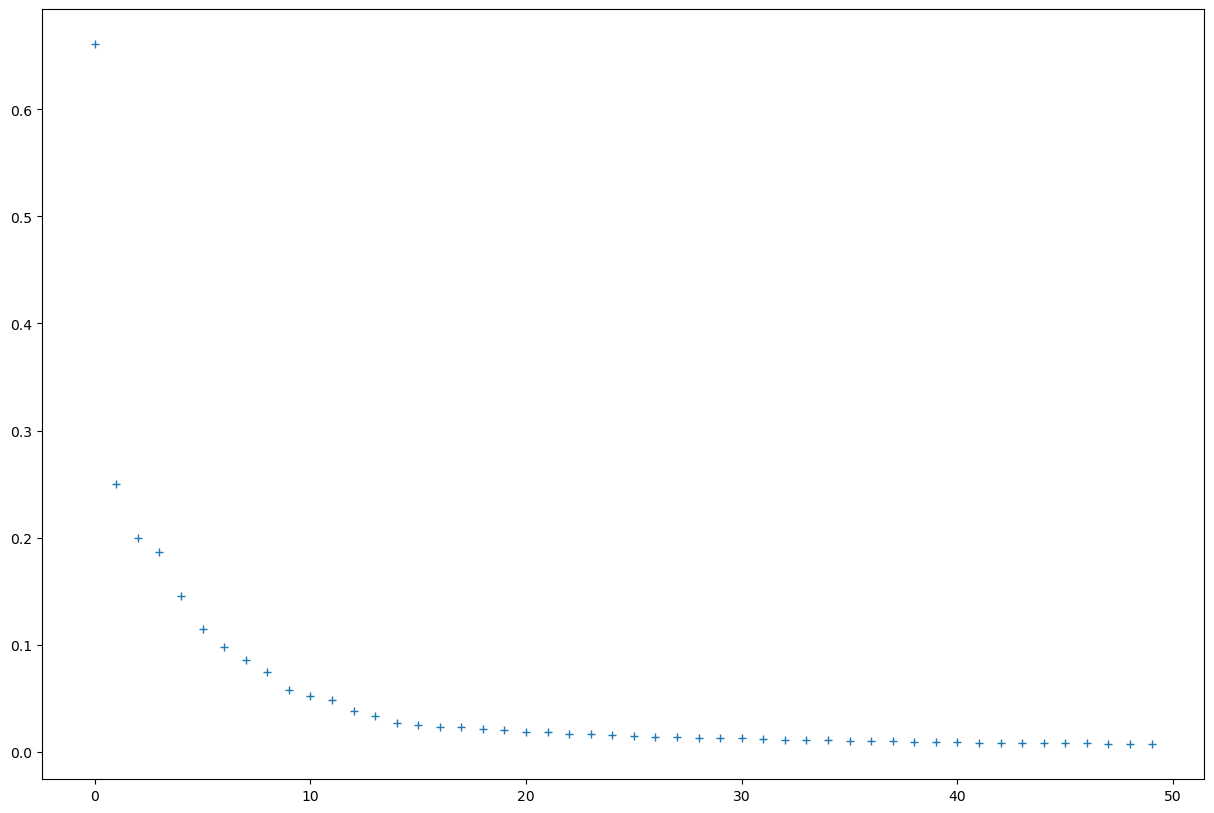

In [61]:
labels_coarse_deflated_sigma0_8, S_coarse_deflated_sigma0_8 = computeSpectralClustering_deflated('Xtt_ERA5_transposed_24h.npz', sigma=0.8, similarityTolerance=0.01, tciTolerance=0.01, tciSweeps=10)

In [64]:
# WARNING deflated variant needs smaller tolerance (of the deflated Gaussian RBF) for smaller sigma!